In [8]:
import pandas as pd
import os

# CSV file paths
files = {
    "Adults": "/kaggle/input/datasets/kawkabkawkeb/datasetsss/adults.csv",
    "Kids": "/kaggle/input/datasets/kawkabkawkeb/datasetsss/kids.csv",
    "Experts": "/kaggle/input/datasets/kawkabkawkeb/datasetsss/experts.csv"
}

total_records = 0
datasets = []

for name, path in files.items():
    if os.path.exists(path):
        df = pd.read_csv(path)

        # Add the Type feature before merging
        df["Type"] = name

        records = len(df)
        total_records += records
        datasets.append(df)

        print(f"{name}: {records:,} records")
        print(f"   Columns: {len(df.columns)}")
        print(f'   Type value: "{name}"')
    else:
        print(f"{name}: File not found -> {path}")

print("-" * 40)
print(f"Total records across all files: {total_records:,}")

# Merge all datasets
if datasets:
    merged_df = pd.concat(datasets, ignore_index=True)

    # Shuffle records so Adults, Kids, and Experts are mixed
    merged_df = merged_df.sample(
        frac=1,
        random_state=42
    ).reset_index(drop=True)

    # Save the merged dataset
    output_path = "/kaggle/working/merged_dataset.csv"
    merged_df.to_csv(output_path, index=False)

    print("-" * 40)
    print(f"Merged dataset records: {len(merged_df):,}")
    print("\nRecords per Type:")
    print(merged_df["Type"].value_counts())

    print("\nFinal columns:")
    print(merged_df.columns.tolist())

    print(f"\nSaved successfully to: {output_path}")

Adults: 3,000 records
   Columns: 14
   Type value: "Adults"
Kids: 3,000 records
   Columns: 14
   Type value: "Kids"
Experts: 3,000 records
   Columns: 14
   Type value: "Experts"
----------------------------------------
Total records across all files: 9,000
----------------------------------------
Merged dataset records: 9,000

Records per Type:
Type
Experts    3000
Adults     3000
Kids       3000
Name: count, dtype: int64

Final columns:
['ID', 'original', 'Summary_Kids', 'Summary_Adult', 'Summary_Expert', 'lenght_original', 'lenght_kids', 'lenght_adult', 'lenght_expert', 'category_orginal', 'category_kids', 'category_adult', 'category_expert ', 'Type', 'category_expert']

Saved successfully to: /kaggle/working/merged_dataset.csv


In [26]:
import pandas as pd
import os

# Input file paths
base_path = "/kaggle/input/datasets/kawkabkawkeb/datasetsss"

adult_path = os.path.join(base_path, "adults.csv")
kids_path = os.path.join(base_path, "kids.csv")
experts_path = os.path.join(base_path, "experts.csv")

# Load datasets
adult_df = pd.read_csv(adult_path)
adult_df["Type"]="Adults"
adult_df = adult_df.rename(columns={"category_expert ": "category_expert"})
kids_df = pd.read_csv(kids_path)
kids_df["Type"]="Kids"

experts_df = pd.read_csv(experts_path)
experts_df["Type"]="Experts"
experts_df = experts_df.rename(columns={"category_expert ": "category_expert"})

print(experts_df.columns.tolist())
print(adult_df.columns.tolist())
print(kids_df.columns.tolist())


# Display original dataset sizes
print("Original dataset sizes:")
print(f"Adult:   {len(adult_df):,} records")
print(f"Kids:    {len(kids_df):,} records")
print(f"Experts: {len(experts_df):,} records")

# Merge datasets vertically (append rows)
merged_df = pd.concat(
    [adult_df, kids_df, experts_df],
    ignore_index=True
)

# Display merged dataset information
print("\nMerged dataset:")
print(f"Total records: {len(merged_df):,}")
print(f"Total columns: {len(merged_df.columns)}")
print("\nColumn names:")
print(merged_df.columns.tolist())

# Save the merged dataset to Kaggle's writable output directory
output_path = "/kaggle/working/finall.csv"
merged_df.to_csv(output_path, index=False, encoding="utf-8")

print(f"\nMerged dataset saved to: {merged_df.head(5)}")

['ID', 'original', 'Summary_Kids', 'Summary_Adult', 'Summary_Expert', 'lenght_original', 'lenght_kids', 'lenght_adult', 'lenght_expert', 'category_orginal', 'category_kids', 'category_adult', 'category_expert', 'Type']
['ID', 'original', 'Summary_Kids', 'Summary_Adult', 'Summary_Expert', 'lenght_original', 'lenght_kids', 'lenght_adult', 'lenght_expert', 'category_orginal', 'category_kids', 'category_adult', 'category_expert', 'Type']
['ID', 'original', 'Summary_Kids', 'Summary_Adult', 'Summary_Expert', 'lenght_original', 'lenght_kids', 'lenght_adult', 'lenght_expert', 'category_orginal', 'category_kids', 'category_adult', 'category_expert', 'Type']
Original dataset sizes:
Adult:   3,000 records
Kids:    3,000 records
Experts: 3,000 records

Merged dataset:
Total records: 9,000
Total columns: 14

Column names:
['ID', 'original', 'Summary_Kids', 'Summary_Adult', 'Summary_Expert', 'lenght_original', 'lenght_kids', 'lenght_adult', 'lenght_expert', 'category_orginal', 'category_kids', 'cate

In [2]:
# =====================================================================
# تلخيص عربي حسب الجمهور - النسخة النهائية المُحسَّنة
#
# التحسينات الرئيسية:
# 1. إصلاح BaseModelOutput بدلاً من tuple في encoder_outputs
# 2. إزالة الـ debug prints لتسريع التدريب
# 3. تعديل BETA values لتكون متوازنة
# 4. إضافة Gradient Clipping
# 5. زيادة logging_steps لعرض متوسط أدق
# 6. التجميد الجزئي في المرحلة الثانية لتسريع التقارب
# =====================================================================

import os
import re
import json
import math
import inspect
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from tqdm import tqdm
from datasets import Dataset
import evaluate
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix
nltk.download("wordnet", quiet=True)
nltk.download("punkt", quiet=True)

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    GenerationConfig,
    set_seed,
    TrainerCallback,
)
from transformers.modeling_outputs import Seq2SeqLMOutput, BaseModelOutput

# ======================
# الإعدادات
# ======================
MODEL_NAME = "Osame1/AraT5-msa-small-finetuned-xlsum-ar"
DATA_FILE  = "/kaggle/input/datasets/kawkabkawkeb/final3/finall.csv"
OUTPUT_DIR = "/kaggle/working/aud_v2"

COL_ID   = "ID"
COL_TEXT = "original"
COL_TYPE = "Type"
AUDIENCE_COLS = {
    "kids":   "Summary_Kids",
    "adult":  "Summary_Adult",
    "expert": "Summary_Expert",
}
AUDIENCE_TYPES = ["kids", "adult", "expert"]
AUD2ID = {a: i for i, a in enumerate(AUDIENCE_TYPES)}
 
TYPE_MAP = {
    "Kids":    "kids",
    "Adults":  "adult",
    "Experts": "expert",
    "kids":    "kids",
    "adult":   "adult",
    "adults":  "adult",
    "expert":  "expert",
    "experts": "expert",
    "أطفال":   "kids",
    "بالغون":  "adult",
    "خبراء":   "expert",
}
 
MAX_INPUT_LENGTH  = 512
MAX_TARGET_LENGTH = 192
BATCH_SIZE        = 8   # ← زيادة من 4 إلى 8
GRADIENT_ACCUMULATION_STEPS = 2  # ← تقليل من 4 إلى 2
EPOCHS_STAGE1     = 1
EPOCHS_STAGE2     = 12  # ← زيادة من 10 إلى 12
 
LR                  = 1e-4  # ← تخفيض من 2e-4 إلى 1e-4
LR_CLASSIFIER       = 2e-4
LR_BASE_MULTIPLIER  = 1.0
 
SEED = 42
 
# ✅ قيم BETA متوازنة (الأهم: BETA_STYLE = 0.0)
BETA_SALIENCE   = 0.1
BETA_AUDIENCE   = 0.2
BETA_DISTANCE   = 0.1
BETA_STYLE      = 0.0  # ← تعطيل Style Loss نهائياً
 
WARMUP_RATIO    = 0.15  # ← زيادة من 0.1 إلى 0.15
LAYERS_TO_UNFREEZE = 4
 
STYLE_TARGETS = {
    "kids":   torch.tensor([4.5, 0.15]),
    "adult":  torch.tensor([4.0, 0.18]),
    "expert": torch.tensor([3.5, 0.22]),
}
STYLE_T = torch.stack([STYLE_TARGETS[a] for a in AUDIENCE_TYPES]).float()
 
AUDIENCE_GENERATION_CONFIGS = {
    "kids": {
        "num_beams": 4, "length_penalty": 0.6, "no_repeat_ngram_size": 3,
        "max_new_tokens": 80, "min_new_tokens": 15, "repetition_penalty": 1.0,
        "early_stopping": True, "do_sample": False,
    },
    "adult": {
        "num_beams": 4, "length_penalty": 1.0, "no_repeat_ngram_size": 3,
        "max_new_tokens": 120, "min_new_tokens": 30, "repetition_penalty": 1.1,
        "early_stopping": True, "do_sample": False,
    },
    "expert": {
        "num_beams": 6, "length_penalty": 1.5, "no_repeat_ngram_size": 3,
        "max_new_tokens": 160, "min_new_tokens": 50, "repetition_penalty": 1.1,
        "early_stopping": False, "do_sample": False,
    },
}
 
DEFAULT_GENERATION_CONFIG = {
    "num_beams": 4, "length_penalty": 1.0, "no_repeat_ngram_size": 3,
    "early_stopping": True, "do_sample": False,
    "min_length": 10, "repetition_penalty": 1.0,
}
 
set_seed(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🖥️ الجهاز المستخدم: {device}")
_use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
print(f"🔢 وضع الدقة: {'bf16' if _use_bf16 else 'float32'}")
 
_TOK_KW = "processing_class" if "processing_class" in inspect.signature(
    Seq2SeqTrainer.__init__).parameters else "tokenizer"
 
# ======================
# تحميل البيانات
# ======================
def load_wide_csv(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"الملف '{path}' غير موجود.")
    df = pd.read_csv(path)

    df = df.sample(frac=1, random_state=42).reset_index(drop=True)
    df["ID"] = range(1, len(df) + 1)
    df.columns = [c.strip() for c in df.columns]
 
    needed = [COL_ID, COL_TEXT, COL_TYPE] + list(AUDIENCE_COLS.values())
    missing = [c for c in needed if c not in df.columns]
    if missing:
        raise ValueError(
            f"أعمدة مفقودة: {missing}\n"
            f"الموجودة: {list(df.columns)}\n"
            f"تأكد أن عمود 'Type' موجود في ملف CSV."
        )
 
    df = df[needed].dropna()
    for c in needed[1:]:
        df[c] = df[c].astype(str).str.strip()
    df = df[(df[needed[1:]] != "").all(axis=1)]
    df = df.drop_duplicates(subset=COL_ID).reset_index(drop=True)
 
    raw_type = df[COL_TYPE].str.strip()
    df[COL_TYPE] = raw_type.map(TYPE_MAP)
    bad_types = df[COL_TYPE].isna()
    if bad_types.any():
        unique_bad = raw_type[bad_types].unique()
        print(f"⚠️ قيم غير معروفة في عمود Type: {unique_bad}")
        print(f"   القيم المقبولة: {list(TYPE_MAP.keys())}")
        print(f"   أضفها إلى TYPE_MAP ← سيتم حذف {bad_types.sum()} صف")
        df = df[~bad_types].reset_index(drop=True)
 
    ok = np.ones(len(df), dtype=bool)
    for col in AUDIENCE_COLS.values():
        ok &= df[col].str.split().str.len().values >= 3
    df = df[ok].reset_index(drop=True)
 
    print(f"\n📊 عدد النصوص: {len(df)}  (×3 = {len(df)*3} مثال تدريب للتلخيص)")
    print(f"📊 توزيع عمود Type:")
    print(df[COL_TYPE].value_counts().to_string())
 
    stats = {a: df[c].str.split().str.len() for a, c in AUDIENCE_COLS.items()}
    for a in AUDIENCE_TYPES:
        s = stats[a]
        print(f"  {a:7s}: mean={s.mean():6.1f} median={s.median():6.1f} "
              f"p5={s.quantile(.05):5.1f} p95={s.quantile(.95):6.1f} كلمة")
    return df
 
 
wide_df = load_wide_csv(DATA_FILE)
 
_rng = np.random.RandomState(SEED)
_ids = wide_df[COL_ID].values.copy()
_rng.shuffle(_ids)
_n_test = max(1, int(0.05 * len(_ids)))
_n_val  = max(1, int(0.05 * len(_ids)))
test_ids  = set(_ids[:_n_test])
val_ids   = set(_ids[_n_test:_n_test + _n_val])
train_ids = set(_ids[_n_test + _n_val:])
 
train_wide = wide_df[wide_df[COL_ID].isin(train_ids)].reset_index(drop=True)
val_wide   = wide_df[wide_df[COL_ID].isin(val_ids)].reset_index(drop=True)
test_wide  = wide_df[wide_df[COL_ID].isin(test_ids)].reset_index(drop=True)
print(f"نصوص: train={len(train_wide)} | val={len(val_wide)} | test={len(test_wide)}")
 
with open(os.path.join(OUTPUT_DIR, "split_ids.json"), "w") as f:
    json.dump({"train": [str(i) for i in train_ids],
               "val":   [str(i) for i in val_ids],
               "test":  [str(i) for i in test_ids]}, f)
 
 
def to_classifier_dataset(frame):
    data = {"id": [], "text": [], "audience_label": []}
    for _, r in frame.iterrows():
        aud = r[COL_TYPE]
        if aud not in AUD2ID:
            continue
        data["id"].append(str(r[COL_ID]))
        data["text"].append(r[COL_TEXT])
        data["audience_label"].append(AUD2ID[aud])
    return Dataset.from_dict(data)
 
 
def to_long_dataset(frame):
    data = {"id": [], "text": [], "summary": [], "audience": []}
    for _, r in frame.iterrows():
        for aud, col in AUDIENCE_COLS.items():
            data["id"].append(str(r[COL_ID]))
            data["text"].append(r[COL_TEXT])
            data["summary"].append(r[col])
            data["audience"].append(aud)
    return Dataset.from_dict(data)
 
 
train_cls_ds = to_classifier_dataset(train_wide)
val_cls_ds   = to_classifier_dataset(val_wide)
test_cls_ds  = to_classifier_dataset(test_wide)
 
train_text_ds = to_long_dataset(train_wide)
val_text_ds   = to_long_dataset(val_wide)
test_text_ds  = to_long_dataset(test_wide)
 
print(f"\n📋 مجموعة المصنّف (المرحلة 1):")
print(f"  train={len(train_cls_ds)} | val={len(val_cls_ds)} | test={len(test_cls_ds)}")
print(f"📋 مجموعة التلخيص (المرحلة 2):")
print(f"  train={len(train_text_ds)} | val={len(val_text_ds)} | test={len(test_text_ds)}")
 
# ======================
# المعالج النصي
# ======================
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.eos_token_id if tokenizer.eos_token_id is not None else 0
 
AUDIENCE_TEMPLATES = {
    "kids": (
        "ملخص للأطفال: أنت مساعد متخصص في تبسيط المعلومات للأطفال. "
        "لخّص النص لطفل عمره 8 إلى 12 سنة بكلمات بسيطة وجمل قصيرة وبدون مصطلحات علمية.\n"
        "النص:\n{text}"
    ),
    "adult": (
        "ملخص للقراء: أنت محرر متخصص بالكتابة للقراء العامين المثقفين. "
        "لخّص النص لبالغ غير متخصص بلغة واضحة ومتوازنة مع شرح المصطلحات التقنية باختصار.\n"
        "النص:\n{text}"
    ),
    "expert": (
        "ملخص للمتخصصين: أنت محلل متخصص يكتب للخبراء. "
        "لخّص النص لمتخصص باستخدام المصطلحات التقنية الدقيقة وبجمل تحليلية تحافظ على الدقة المفاهيمية.\n"
        "النص:\n{text}"
    ),
}
 
HEADER_IDS = {
    a: set(tokenizer(AUDIENCE_TEMPLATES[a].replace("{text}", ""),
                     add_special_tokens=False)["input_ids"])
    for a in AUDIENCE_TYPES
}
SPECIAL_IDS = set(tokenizer.all_special_ids)
 
 
def prompt_with_audience(texts, audiences):
    return [AUDIENCE_TEMPLATES[aud].format(text=t) for t, aud in zip(texts, audiences)]
 
 
CLASSIFIER_PREFIX = "صنّف جمهور النص:\n"
 
def preprocess_classifier(examples):
    texts = [CLASSIFIER_PREFIX + t for t in examples["text"]]
    enc = tokenizer(texts, max_length=MAX_INPUT_LENGTH,
                    truncation=True, padding="max_length")
    return {
        "input_ids":       enc["input_ids"],
        "attention_mask":  enc["attention_mask"],
        "labels":          [[l] for l in examples["audience_label"]],
        "audience_labels": examples["audience_label"],
    }
 
 
# ✅ النسخة المُحسَّنة: بدون padding ثابت، الـ Collator سيتكفل به
def preprocess_seq2seq(examples):
    prompted = prompt_with_audience(examples["text"], examples["audience"])
    targets, audiences = examples["summary"], examples["audience"]

    enc_prompted = tokenizer(prompted, max_length=MAX_INPUT_LENGTH, truncation=True)
    enc_targets = tokenizer(text_target=targets, max_length=MAX_TARGET_LENGTH, truncation=True)

    labels_list, salience_list, audience_labels_list = [], [], []

    for inp_ids, target_ids, aud in zip(enc_prompted["input_ids"], enc_targets["input_ids"], audiences):
        target_set = set(target_ids) - set(tokenizer.all_special_ids)
        salience = [1 if (tok in target_set and tok not in HEADER_IDS[aud]) else 0 for tok in inp_ids]

        labels_list.append(target_ids)
        salience_list.append(salience)
        audience_labels_list.append(AUD2ID[aud])

    return {
        "input_ids": enc_prompted["input_ids"],
        "attention_mask": enc_prompted["attention_mask"],
        "labels": labels_list,
        "salience_labels": salience_list,
        "audience_labels": audience_labels_list,
        "summary_input_ids": enc_targets["input_ids"],
        "summary_attention_mask": [[1] * len(ids) for ids in enc_targets["input_ids"]],
    }
 
 
def tokenize_cls_ds(ds):
    return ds.map(preprocess_classifier, batched=True, remove_columns=ds.column_names)
 
def tokenize_seq_ds(ds):
    return ds.map(preprocess_seq2seq, batched=True, remove_columns=ds.column_names)
 
 
train_cls_tok = tokenize_cls_ds(train_cls_ds)
eval_cls_tok  = tokenize_cls_ds(val_cls_ds)
 
train_ds = tokenize_seq_ds(train_text_ds)
eval_ds  = tokenize_seq_ds(val_text_ds)
 
print(f"✅ بيانات المصنّف: train={len(train_cls_tok)} | val={len(eval_cls_tok)}")
print(f"✅ بيانات التلخيص: train={len(train_ds)} | val={len(eval_ds)}")
 
 
# ======================
# النموذج الرئيسي
# ======================
class AudienceAwareT5(nn.Module):
    main_input_name = "input_ids"
 
    def __init__(self, name, adapter_dim=256, num_audiences=3):
        super().__init__()
        self.base = AutoModelForSeq2SeqLM.from_pretrained(name)
        d = self.base.config.d_model
 
        self.audience_embedding = nn.Embedding(num_audiences, d)
        self.adapter = nn.Sequential(
            nn.Linear(d, adapter_dim), nn.ReLU(), nn.Linear(adapter_dim, d)
        )
        self.sent_proj     = nn.Linear(d, d)
        self.salience_head = nn.Linear(d, 1)
        self.audience_attention = nn.Sequential(
            nn.Linear(d, d // 2), nn.Tanh(), nn.Linear(d // 2, 1)
        )
 
        self.audience_classifier = nn.Sequential(
            nn.Linear(d, d // 2), nn.ReLU(), nn.LayerNorm(d // 2), nn.Dropout(0.1),
            nn.Linear(d // 2, d // 4), nn.ReLU(), nn.LayerNorm(d // 4),
            nn.Linear(d // 4, num_audiences)
        )
 
        nn.init.normal_(self.audience_embedding.weight, std=0.02)
        nn.init.zeros_(self.adapter[2].weight); nn.init.zeros_(self.adapter[2].bias)
        nn.init.normal_(self.sent_proj.weight, std=0.02); nn.init.zeros_(self.sent_proj.bias)
 
        self.config = self.base.config
        self.register_buffer("class_weights", torch.ones(num_audiences))
        self._custom_modules = [
            "audience_embedding", "adapter", "sent_proj",
            "salience_head", "audience_attention", "audience_classifier"
        ]
        self.training_stage = "joint"
 
    def prepare_inputs_for_generation(self, *args, **kwargs):
        return self.base.prepare_inputs_for_generation(*args, **kwargs)
 
    def _reorder_cache(self, *args, **kwargs):
        return self.base._reorder_cache(*args, **kwargs)
 
    @property
    def generation_config(self):
        return self.base.generation_config
 
    @generation_config.setter
    def generation_config(self, value):
        self.base.generation_config = value
 
    def sentence_context(self, hidden, attention_mask):
        B, T, D = hidden.shape
        chunk = 20
        ctx = torch.zeros_like(hidden)
        for i in range(0, T, chunk):
            h = hidden[:, i:i + chunk, :]
            m = attention_mask[:, i:i + chunk].unsqueeze(-1).to(hidden.dtype)
            pooled = (h * m).sum(1) / (m.sum(1) + 1e-8)
            ctx[:, i:i + chunk, :] = self.sent_proj(pooled).unsqueeze(1)
        return ctx
 
    def encode(self, input_ids, attention_mask, audience_labels=None):
        enc_out = self.base.encoder(input_ids=input_ids, attention_mask=attention_mask,
                                    return_dict=True)
        H = enc_out.last_hidden_state
        if audience_labels is not None:
            aud_emb = self.audience_embedding(audience_labels)
            H = H + aud_emb.unsqueeze(1).expand(-1, H.size(1), -1) * 0.7
        H = H + self.sentence_context(H, attention_mask)
        H = H + self.adapter(H)
        return H
 
    def classify_text(self, input_ids, attention_mask):
        enc = self.base.encoder(input_ids=input_ids, attention_mask=attention_mask,
                                return_dict=True)
        h = enc.last_hidden_state
        m = attention_mask.unsqueeze(-1).to(h.dtype)
        pooled = (h * m).sum(1) / m.sum(1).clamp(min=1.0)
        return self.audience_classifier(pooled)
 
    def classify_summary(self, summary_ids, summary_mask):
        enc = self.base.encoder(input_ids=summary_ids, attention_mask=summary_mask,
                                return_dict=True)
        h = enc.last_hidden_state
        m = summary_mask.unsqueeze(-1).to(h.dtype)
        pooled = (h * m).sum(1) / m.sum(1).clamp(min=1.0)
        return self.audience_classifier(pooled)
 
    def distance_loss(self):
        w = F.normalize(self.audience_embedding.weight, p=2, dim=-1)
        sim = w @ w.t()
        return F.mse_loss(sim, torch.eye(sim.size(0), device=sim.device))
 
    # ✅ النسخة المُحسَّنة: Softmax كامل بدلاً من TopK
    def style_consistency_loss(self, logits, audience_labels, labels):
        mask = (labels != -100).float()
        if mask.sum() == 0:
            return torch.tensor(0.0, device=logits.device, requires_grad=True)

        probs = F.softmax(logits.float(), dim=-1)
        ent = -(probs * (probs + 1e-9).log()).sum(-1)
        max_prob = probs.max(-1)[0]

        den = mask.sum(-1).clamp(min=1.0)
        avg_entropy = (ent * mask).sum(-1) / den
        avg_max_prob = (max_prob * mask).sum(-1) / den

        tgt = STYLE_T.to(logits.device)[audience_labels]
        loss_ent = F.mse_loss(avg_entropy, tgt[:, 0])
        loss_conf = F.mse_loss(avg_max_prob, tgt[:, 1])
        total_style_loss = loss_ent + loss_conf
        
        if not torch.isfinite(total_style_loss):
            return torch.tensor(0.0, device=logits.device, requires_grad=True)
        return total_style_loss
 
    # ✅ النسخة المُحسَّنة: BaseModelOutput بدلاً من tuple، بدون debug prints
    def forward(self, input_ids=None, attention_mask=None, labels=None,
                salience_labels=None, audience_labels=None,
                summary_input_ids=None, summary_attention_mask=None, **kwargs):

        if self.training_stage == "classifier":
            text_logits = self.classify_text(input_ids, attention_mask)

            total_loss = torch.tensor(0.0, device=input_ids.device)
            if audience_labels is not None:
                aud_loss = F.cross_entropy(
                    text_logits.float(), audience_labels,
                    weight=self.class_weights.to(text_logits.device), reduction="mean")
                if torch.isfinite(aud_loss):
                    total_loss = total_loss + aud_loss

            if BETA_DISTANCE > 0:
                d_loss = self.distance_loss()
                if torch.isfinite(d_loss):
                    total_loss = total_loss + BETA_DISTANCE * d_loss

            if not torch.isfinite(total_loss):
                total_loss = torch.tensor(0.0, device=input_ids.device, requires_grad=True)

            return Seq2SeqLMOutput(loss=total_loss, logits=text_logits)

        audience_logits = None
        if summary_input_ids is not None and summary_attention_mask is not None:
            audience_logits = self.classify_summary(summary_input_ids, summary_attention_mask)

        H = self.encode(input_ids, attention_mask, audience_labels)
        salience_logits = self.salience_head(H).squeeze(-1)

        # ✅ الإصلاح الجوهري: BaseModelOutput
        encoder_outputs_obj = BaseModelOutput(last_hidden_state=H)
        
        decoder_outputs = self.base(
            attention_mask=attention_mask,
            encoder_outputs=encoder_outputs_obj,
            labels=labels,
            return_dict=True,
        )
        
        total_loss = (decoder_outputs.loss if decoder_outputs.loss is not None
                      else torch.tensor(0.0, device=H.device))

        if salience_labels is not None and BETA_SALIENCE > 0:
            bce = F.binary_cross_entropy_with_logits(
                salience_logits.float(), salience_labels.float(), reduction="none")
            m = attention_mask.float()
            sal_loss = (bce * m).sum() / m.sum().clamp(min=1.0)
            if torch.isfinite(sal_loss):
                total_loss = total_loss + BETA_SALIENCE * sal_loss

        if audience_labels is not None and BETA_AUDIENCE > 0 and audience_logits is not None:
            aud_loss = F.cross_entropy(
                audience_logits.float(), audience_labels,
                weight=self.class_weights.to(audience_logits.device), reduction="mean")
            if torch.isfinite(aud_loss):
                total_loss = total_loss + BETA_AUDIENCE * aud_loss

        if BETA_DISTANCE > 0:
            d_loss = self.distance_loss()
            if torch.isfinite(d_loss):
                total_loss = total_loss + BETA_DISTANCE * d_loss

        if (audience_labels is not None and labels is not None and BETA_STYLE > 0
                and decoder_outputs.logits is not None
                and torch.isfinite(decoder_outputs.logits).all()):
            s_loss = self.style_consistency_loss(decoder_outputs.logits, audience_labels, labels)
            if torch.isfinite(s_loss):
                total_loss = total_loss + BETA_STYLE * s_loss

        if not torch.isfinite(total_loss):
            total_loss = torch.tensor(0.0, device=H.device, requires_grad=True)

        decoder_outputs.loss = total_loss
        decoder_outputs.audience_logits = audience_logits
        decoder_outputs.salience_logits = salience_logits
        return decoder_outputs
 
    @torch.no_grad()
    def generate(self, input_ids=None, attention_mask=None, audience_labels=None, **kwargs):
        for key in ["salience_labels", "summary_input_ids", "summary_attention_mask",
                    "labels", "decoder_input_ids", "decoder_attention_mask"]:
            kwargs.pop(key, None)
        kwargs.setdefault("use_cache", True)
        kwargs.setdefault("decoder_start_token_id", tokenizer.pad_token_id)
        kwargs.setdefault("eos_token_id", tokenizer.eos_token_id)
 
        H = self.encode(input_ids, attention_mask, audience_labels)
 
        if kwargs.get("use_cache", True) and "past_key_values" not in kwargs:
            try:
                from transformers import EncoderDecoderCache, DynamicCache
                kwargs["past_key_values"] = EncoderDecoderCache(DynamicCache(), DynamicCache())
            except Exception:
                kwargs["use_cache"] = False
 
        return self.base.generate(
            encoder_outputs=BaseModelOutput(last_hidden_state=H),
            attention_mask=attention_mask,
            **kwargs
        )
 
    def predict_audience(self, text, tokenizer, device="cuda"):
        self.eval()
        if isinstance(device, str):
            device = torch.device(device)
        self.to(device)
        prefixed = CLASSIFIER_PREFIX + text
        inputs = tokenizer(prefixed, return_tensors="pt",
                           max_length=MAX_INPUT_LENGTH, truncation=True).to(device)
        with torch.no_grad():
            logits = self.classify_text(inputs.input_ids, inputs.attention_mask)
            probs  = F.softmax(logits.float(), dim=-1)
            pred_idx = torch.argmax(probs, dim=-1)
        return pred_idx.item(), probs[0].cpu().numpy()
 
    def save_pretrained(self, save_directory, **kwargs):
        os.makedirs(save_directory, exist_ok=True)
        self.base.save_pretrained(save_directory, safe_serialization=False)
        custom_state = {}
        for name in self._custom_modules:
            custom_state[name] = {k: v.cpu() for k, v in getattr(self, name).state_dict().items()}
        custom_state["class_weights"] = self.class_weights.cpu()
        custom_state["config"] = {
            "adapter_dim":   self.adapter[0].out_features,
            "num_audiences": self.audience_classifier[-1].out_features,
        }
        torch.save(custom_state, os.path.join(save_directory, "custom_modules.pt"))
        self.config.save_pretrained(save_directory)
        print(f"✅ تم حفظ النموذج في {save_directory}")
 
    @classmethod
    def from_pretrained(cls, save_directory, **kwargs):
        custom_path = os.path.join(save_directory, "custom_modules.pt")
        custom_state = torch.load(custom_path, map_location="cpu", weights_only=False)
        cfg = custom_state.get("config", {})
        model = cls(save_directory,
                    adapter_dim=cfg.get("adapter_dim", 256),
                    num_audiences=cfg.get("num_audiences", 3), **kwargs)
        for mod_name in model._custom_modules:
            if mod_name in custom_state:
                getattr(model, mod_name).load_state_dict(custom_state[mod_name])
        if "class_weights" in custom_state:
            model.class_weights = custom_state["class_weights"]
        print(f"✅ تم تحميل النموذج من {custom_path}")
        return model
 
    def unfreeze_top_encoder_layers(self, num_layers=4):
        total_layers = self.base.config.num_layers
        for name, param in self.base.encoder.named_parameters():
            parts = name.split(".")
            if parts[0] == "block" and len(parts) > 1 and parts[1].isdigit():
                if int(parts[1]) >= total_layers - num_layers:
                    param.requires_grad = True
            elif parts[0] == "final_layer_norm":
                param.requires_grad = True
 
    def check_audience_separation(self):
        aud_embs = self.audience_embedding.weight.detach()
        print("\n📏 مصفوفة التشابه/التباعد بين الجماهير:")
        print("-" * 60)
        distances = []
        for i, aud1 in enumerate(AUDIENCE_TYPES):
            row_sim, row_dist = [], []
            for j, aud2 in enumerate(AUDIENCE_TYPES):
                if i == j:
                    row_sim.append(1.0); row_dist.append(0.0)
                else:
                    sim = F.cosine_similarity(aud_embs[i].unsqueeze(0),
                                              aud_embs[j].unsqueeze(0), dim=-1).item()
                    sim = max(-1.0, min(1.0, sim)); dist = 1 - sim
                    row_sim.append(sim); row_dist.append(dist)
                    if i < j:
                        distances.append((aud1, aud2, sim, dist))
            print(f"{aud1:8s} sim:  {'  '.join(f'{s:6.3f}' for s in row_sim)}")
            print(f"{'':8s} dist: {'  '.join(f'{d:6.3f}' for d in row_dist)}")
        print("-" * 60)
        avg_dist = 0.0
        for aud1, aud2, sim, dist in distances:
            status = "✅ جيد" if dist >= 0.30 else "⚠️ ضعيف"
            print(f"  {aud1:8s} vs {aud2:8s}: sim={sim:.3f} | dist={dist:.3f} {status}")
            avg_dist += dist
        avg_dist /= max(len(distances), 1)
        print(f"\n🎯 متوسط التباعد: {avg_dist:.3f} {'✅' if avg_dist >= 0.30 else '⚠️'}")
        return avg_dist
 
 
# ======================
# تهيئة النموذج
# ======================
model = AudienceAwareT5(MODEL_NAME, num_audiences=len(AUDIENCE_TYPES))
model.config.decoder_start_token_id = tokenizer.pad_token_id
 
_train_type_ids = np.array(train_cls_ds["audience_label"])
class_weights_vals = compute_class_weight(
    "balanced", classes=np.unique(_train_type_ids), y=_train_type_ids)
model.class_weights = torch.tensor(class_weights_vals, dtype=torch.float32)
print(f"\n🎯 أوزان الفئات (من Type): {class_weights_vals}")
for i, a in enumerate(AUDIENCE_TYPES):
    count = (_train_type_ids == i).sum()
    print(f"  {a}: {count} نص")
 
 
# ======================
# جامع البيانات
# ======================
class ClassifierCollator:
    def __init__(self, pad_token_id):
        self.pad = pad_token_id
 
    def __call__(self, features):
        input_ids      = torch.tensor([f["input_ids"]      for f in features], dtype=torch.long)
        attention_mask = torch.tensor([f["attention_mask"]  for f in features], dtype=torch.long)
        audience_labels= torch.tensor([f["audience_labels"] for f in features], dtype=torch.long)
        labels         = torch.full((len(features), 1), -100, dtype=torch.long)
        return {
            "input_ids":       input_ids,
            "attention_mask":  attention_mask,
            "audience_labels": audience_labels,
            "labels":          labels,
        }
 
 
# ✅ النسخة المُحسَّنة: Padding ديناميكي للحقول المخصصة
class AudienceAwareCollator(DataCollatorForSeq2Seq):
    def __init__(self, tokenizer, model=None, label_pad_token_id=-100):
        super().__init__(tokenizer=tokenizer, model=model, label_pad_token_id=label_pad_token_id)

    def __call__(self, features):
        salience = [f.pop("salience_labels", None) for f in features]
        audience = [f.pop("audience_labels", None) for f in features]
        sum_ids  = [f.pop("summary_input_ids", None) for f in features]
        sum_mask = [f.pop("summary_attention_mask", None) for f in features]

        batch = super().__call__(features)

        if salience[0] is not None:
            max_in_len = len(batch["input_ids"][0])
            padded_salience = []
            for s in salience:
                pad_len = max_in_len - len(s)
                padded_salience.append(s + [0] * pad_len)
            batch["salience_labels"] = torch.tensor(padded_salience, dtype=torch.float)

        if audience[0] is not None:
            batch["audience_labels"] = torch.tensor(audience, dtype=torch.long)

        if sum_ids[0] is not None:
            max_out_len = len(batch["labels"][0])
            padded_sum_ids = []
            padded_sum_mask = []
            for ids, mask in zip(sum_ids, sum_mask):
                pad_len = max_out_len - len(ids)
                padded_sum_ids.append(ids + [self.tokenizer.pad_token_id] * pad_len)
                padded_sum_mask.append(mask + [0] * pad_len)
            batch["summary_input_ids"] = torch.tensor(padded_sum_ids, dtype=torch.long)
            batch["summary_attention_mask"] = torch.tensor(padded_sum_mask, dtype=torch.long)

        return batch
 
 
cls_collator = ClassifierCollator(pad_token_id=tokenizer.pad_token_id)
seq_collator = AudienceAwareCollator(tokenizer, model=None, label_pad_token_id=-100)
 
 
# ======================
# المقاييس
# ======================
bertscore_metric = evaluate.load("bertscore")
chrf_metric      = evaluate.load("chrf")
bleu_metric      = evaluate.load("bleu")
meteor_metric    = evaluate.load("meteor")
rouge_metric     = evaluate.load("rouge")
 
 
def ws_tok(x):
    return x.split()
 
 
def compute_classifier_metrics(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    preds = np.argmax(logits, axis=-1)
    if labels.ndim == 2:
        labels = labels[:, 0]
    return {
        "audience_accuracy": accuracy_score(labels, preds),
        "audience_f1":       f1_score(labels, preds, average="weighted"),
    }
 
 
def avg_sentence_words(text):
    sents = [s for s in re.split(r"[.،؟!?\n]", text) if s.strip()]
    return float(np.mean([len(s.split()) for s in sents])) if sents else 0.0
 
 
def compute_style_metrics(decoded_preds, audiences):
    results = {}
    for aud in AUDIENCE_TYPES:
        aud_preds = [p for p, a in zip(decoded_preds, audiences) if a == aud]
        if not aud_preds:
            continue
        results[f"style_{aud}_avg_words"]      = float(np.mean([len(p.split()) for p in aud_preds]))
        results[f"style_{aud}_avg_sent_words"] = float(np.mean([avg_sentence_words(p) for p in aud_preds]))
    if all(f"style_{a}_avg_words" in results for a in AUDIENCE_TYPES):
        results["style_separation"] = results["style_expert_avg_words"] - results["style_kids_avg_words"]
    return results
 
 
def compute_metrics(eval_pred):
    preds, labels = eval_pred
    if isinstance(preds, tuple):
        preds = preds[0]
    vocab_size = tokenizer.vocab_size
    preds  = np.where(preds  != -100, preds,  tokenizer.pad_token_id)
    preds  = np.clip(preds.astype(np.int64),  0, vocab_size - 1)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    labels = np.clip(labels.astype(np.int64), 0, vocab_size - 1)
    dp = [p.strip() for p in tokenizer.batch_decode(preds,  skip_special_tokens=True)]
    dl = [l.strip() for l in tokenizer.batch_decode(labels, skip_special_tokens=True)]
    bertscore = bertscore_metric.compute(predictions=dp, references=dl, lang="ar")
    chrf      = chrf_metric.compute(predictions=dp, references=dl)
    bleu      = bleu_metric.compute(predictions=dp, references=[[l] for l in dl])
    meteor    = meteor_metric.compute(predictions=dp, references=dl)
    rouge     = rouge_metric.compute(predictions=dp, references=dl, tokenizer=ws_tok)
    return {
        "bertscore_f1": float(np.mean(bertscore["f1"])),
        "chrf":   chrf["score"],
        "bleu":   bleu["bleu"],
        "meteor": meteor["meteor"],
        "rouge1": rouge["rouge1"],
        "rouge2": rouge["rouge2"],
        "rougeL": rouge["rougeL"],
        "gen_len": float(np.mean([len(x.split()) for x in dp])),
    }
 
 
# ======================
# التوقف المبكر
# ======================
class EarlyStoppingCallback(TrainerCallback):
    def __init__(self, patience=3, min_delta=0.0, metric="eval_loss", greater_is_better=False):
        self.patience, self.min_delta = patience, min_delta
        self.metric, self.gib = metric, greater_is_better
        self.best, self.wait, self.best_state = None, 0, None
 
    def on_evaluate(self, args, state, control, metrics=None, model=None, **kwargs):
        val = (metrics or {}).get(self.metric)
        if val is None:
            return
        improved = (self.best is None or
                    (val > self.best + self.min_delta if self.gib else val < self.best - self.min_delta))
        if improved:
            self.best, self.wait = val, 0
            if model is not None:
                self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            self.wait += 1
            if self.wait >= self.patience:
                print(f"\n⚠️ التوقف المبكر: {self.metric} لم يتحسن لمدة {self.patience} تقييمات")
                control.should_training_stop = True
 
    def on_train_end(self, args, state, control, model=None, **kwargs):
        if model is not None and self.best_state is not None:
            model.load_state_dict(self.best_state)
            print(f"✅ تم استرجاع أفضل نموذج ({self.metric} = {self.best:.4f})")
 
 
# ======================
# المدرب المخصص
# ======================
class CustomSeq2SeqTrainer(Seq2SeqTrainer):
 
    def save_model(self, output_dir=None, _internal_call=False):
        output_dir = output_dir or self.args.output_dir
        os.makedirs(output_dir, exist_ok=True)
        self.model.save_pretrained(output_dir)
        tok = getattr(self, "processing_class", None) or getattr(self, "tokenizer", None)
        if tok is not None:
            tok.save_pretrained(output_dir)
 
    def create_optimizer(self):
        if self.optimizer is not None:
            return self.optimizer
        custom_ids = set()
        for mod_name in self.model._custom_modules:
            for p in getattr(self.model, mod_name).parameters():
                custom_ids.add(id(p))
        groups = {}
        for name, p in self.model.named_parameters():
            if not p.requires_grad:
                continue
            is_custom = id(p) in custom_ids
            no_decay = p.ndim == 1 or name.endswith(".bias") or "layer_norm" in name
            key = (is_custom, no_decay)
            groups.setdefault(key, []).append(p)
        param_groups = []
        for (is_custom, no_decay), params in groups.items():
            lr = self.args.learning_rate * (1.0 if is_custom else LR_BASE_MULTIPLIER)
            param_groups.append({
                "params": params, "lr": lr,
                "weight_decay": 0.0 if no_decay else self.args.weight_decay,
            })
        opt_cls, opt_kwargs = self.get_optimizer_cls_and_kwargs(self.args)
        opt_kwargs.pop("lr", None)
        self.optimizer = opt_cls(param_groups, **opt_kwargs)
        return self.optimizer
 
 
def _common_args(**over):
    import inspect as _inspect
    _ta_params = set(_inspect.signature(Seq2SeqTrainingArguments.__init__).parameters)

    warmup_kwargs = {}
    if "warmup_ratio" in _ta_params:
        warmup_kwargs["warmup_ratio"] = WARMUP_RATIO
    elif "warmup_steps" in _ta_params:
        warmup_kwargs["warmup_steps"] = 100

    base = dict(
        lr_scheduler_type="linear", weight_decay=0.01,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=2,
        logging_steps=50,  # ← زيادة من 10 إلى 50
        bf16=_use_bf16, fp16=False,
        report_to="none", seed=SEED, remove_unused_columns=False,
        load_best_model_at_end=False,
        max_grad_norm=1.0,  # ← إضافة Gradient Clipping
        **warmup_kwargs,
    )
    base.update(over)

    safe    = {k: v for k, v in base.items() if k in _ta_params}
    dropped = set(base) - set(safe)
    if dropped:
        print(f"⚠️ تجاهل معاملات غير مدعومة: {dropped}")
    return Seq2SeqTrainingArguments(**safe)
 
 
def make_trainer(model, args, train_ds, eval_ds, collator, callbacks, compute_metrics_fn=None):
    return CustomSeq2SeqTrainer(
        model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
        data_collator=collator, compute_metrics=compute_metrics_fn,
        callbacks=callbacks, **{_TOK_KW: tokenizer},
    )
 
 
# ======================
# دوال التوليد والتقييم
# ======================
@torch.no_grad()
def generate_for_audience(texts, audience, model, tokenizer, device, batch_size=16):
    if audience not in AUDIENCE_TYPES:
        raise ValueError(f"الجمهور يجب أن يكون أحد: {AUDIENCE_TYPES}")
    model.eval(); model.to(device)
    outs = []
    cfg = AUDIENCE_GENERATION_CONFIGS[audience]
    for i in range(0, len(texts), batch_size):
        chunk = [AUDIENCE_TEMPLATES[audience].format(text=t) for t in texts[i:i + batch_size]]
        enc = tokenizer(chunk, return_tensors="pt", padding=True,
                        truncation=True, max_length=MAX_INPUT_LENGTH).to(device)
        aud_ids = torch.full((enc.input_ids.size(0),), AUD2ID[audience],
                             dtype=torch.long, device=device)
        gen = model.generate(
            input_ids=enc.input_ids, attention_mask=enc.attention_mask,
            audience_labels=aud_ids, **cfg,
            decoder_start_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
        outs.extend(s.strip() for s in tokenizer.batch_decode(gen, skip_special_tokens=True))
    return outs
 
 
def summarize_for_audience(text, audience_type="adult", model=None, tokenizer=None, device="cuda"):
    if isinstance(device, str):
        device = torch.device(device)
    return generate_for_audience([text], audience_type, model, tokenizer, device, batch_size=1)[0]
 
 
def summarize_all_audiences(text, model=None, tokenizer=None, device="cuda"):
    if isinstance(device, str):
        device = torch.device(device)
    result = {}
    for aud in AUDIENCE_TYPES:
        s = summarize_for_audience(text, aud, model, tokenizer, device)
        enc = tokenizer(s, return_tensors="pt",
                        max_length=MAX_TARGET_LENGTH, truncation=True).to(device)
        with torch.no_grad():
            logits = model.classify_summary(enc.input_ids, enc.attention_mask)
            probs  = F.softmax(logits.float(), dim=-1)
            pred_idx = torch.argmax(probs, dim=-1).item()
        result[aud] = {
            "summary": s,
            "words": len(s.split()),
            "summary_style_says": AUDIENCE_TYPES[pred_idx],
            "confidence": float(probs[0][pred_idx].cpu()),
        }
    return result
 
 
@torch.no_grad()
def classify_texts_batch(texts, model, tokenizer, device, batch_size=32, use_original=True):
    model.eval(); model.to(device)
    preds = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], return_tensors="pt", padding=True,
                        truncation=True,
                        max_length=MAX_INPUT_LENGTH if use_original else MAX_TARGET_LENGTH
                        ).to(device)
        if use_original:
            logits = model.classify_text(enc.input_ids, enc.attention_mask)
        else:
            logits = model.classify_summary(enc.input_ids, enc.attention_mask)
        preds.extend(torch.argmax(logits, dim=-1).cpu().tolist())
    return np.array(preds)
 
 
def evaluate_audience_accuracy(model, tokenizer, texts, true_audiences, device, tag,
                                use_original=True):
    y_true = np.array([AUD2ID[a] for a in true_audiences])
    y_pred = classify_texts_batch(texts, model, tokenizer, device,
                                  use_original=use_original)
    acc = (y_pred == y_true).mean()
    print(f"\n📊 [{tag}] دقة تصنيف الجمهور: {acc:.2%}")
    print(classification_report(y_true, y_pred, labels=list(range(len(AUDIENCE_TYPES))),
                                target_names=AUDIENCE_TYPES, digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(AUDIENCE_TYPES))))
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=AUDIENCE_TYPES, yticklabels=AUDIENCE_TYPES)
    plt.title(f"Audience confusion matrix - {tag}")
    plt.ylabel("True"); plt.xlabel("Predicted"); plt.tight_layout()
    path = f"{OUTPUT_DIR}/confusion_matrix_{tag}.png"
    plt.savefig(path); plt.close()
    print(f"💾 {path}")
    return float(acc)
 
 
# ======================
# التدريب على مرحلتين
# ======================
def train_stage1_classifier(model, train_cls_tok, eval_cls_tok, epochs=1):
    print("\n" + "=" * 60)
    print("🎯 المرحلة 1: تدريب المصنّف على النص الأصلي (عمود Type)")
    print("=" * 60)
    model.training_stage = "classifier"
 
    for p in model.base.parameters():
        p.requires_grad = False
    model.unfreeze_top_encoder_layers(num_layers=LAYERS_TO_UNFREEZE)
    for m in (model.audience_classifier, model.audience_embedding):
        for p in m.parameters():
            p.requires_grad = True
 
    args1 = _common_args(
        output_dir=f"{OUTPUT_DIR}/stage1",
        learning_rate=LR_CLASSIFIER,
        num_train_epochs=epochs,
        predict_with_generate=False,
        label_names=["audience_labels"],
    )
    tr = make_trainer(
        model, args1, train_cls_tok, eval_cls_tok,
        collator=cls_collator,
        callbacks=[EarlyStoppingCallback(patience=2, metric="eval_audience_accuracy",
                                         greater_is_better=True)],
        compute_metrics_fn=compute_classifier_metrics,
    )
    tr.train()
    res = tr.evaluate()
    print("\n📊 نتائج المرحلة 1:")
    for k, v in res.items():
        print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")
 
    evaluate_audience_accuracy(
        model, tokenizer,
        val_cls_ds["text"],
        [AUDIENCE_TYPES[i] for i in val_cls_ds["audience_label"]],
        device, "stage1_original_texts",
        use_original=True
    )
    model.check_audience_separation()
    print("✅ اكتملت المرحلة 1")
    return model, tr
 
 
# ✅ النسخة المُحسَّنة: تجميد جزئي لتسريع التقارب
def train_stage2_joint(model, train_ds, eval_ds, epochs=12):
    print("\n" + "=" * 60)
    print("🔄 المرحلة 2: التدريب المشترك (محسّن - تجميد جزئي)")
    print("=" * 60)
    model.training_stage = "joint"

    for p in model.parameters():
        p.requires_grad = False

    for m_name in model._custom_modules:
        for p in getattr(model, m_name).parameters():
            p.requires_grad = True

    total_enc_layers = model.base.config.num_layers
    layers_to_unfreeze_enc = max(2, total_enc_layers // 2)
    
    for name, param in model.base.encoder.named_parameters():
        parts = name.split(".")
        if parts[0] == "block" and len(parts) > 1 and parts[1].isdigit():
            layer_idx = int(parts[1])
            if layer_idx >= total_enc_layers - layers_to_unfreeze_enc:
                param.requires_grad = True
        elif "final_layer_norm" in name:
            param.requires_grad = True

    for param in model.base.decoder.parameters():
        param.requires_grad = True
        
    if hasattr(model.base, 'lm_head'):
        for param in model.base.lm_head.parameters():
            param.requires_grad = True

    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"✅ بارامترات قابلة للتدريب: {trainable_params:,} / {total_params:,} ({100*trainable_params/total_params:.1f}%)")

    args2 = _common_args(
        output_dir=OUTPUT_DIR, 
        learning_rate=LR,
        num_train_epochs=epochs,
        predict_with_generate=True,
        generation_max_length=MAX_TARGET_LENGTH,
        generation_config=GenerationConfig(**DEFAULT_GENERATION_CONFIG),
        label_names=["labels"],
        logging_dir=f"{OUTPUT_DIR}/logs",
    )
    
    tr = make_trainer(
        model, args2, train_ds, eval_ds,
        collator=seq_collator,
        callbacks=[EarlyStoppingCallback(patience=4, metric="eval_rougeL", greater_is_better=True)],
        compute_metrics_fn=compute_metrics,
    )
    tr.train()
    return tr
 
 
# ======================
# بدء التدريب
# ======================
print("\n🏁 بدء التدريب ثنائي المراحل...")
print(f"📋 المرحلة 1: مصنّف على النص الأصلي (عمود Type) | {EPOCHS_STAGE1} حقبة")
print(f"📋 المرحلة 2: تلخيص لـ 3 جماهير                 | {EPOCHS_STAGE2} حقبة")
 
model, _ = train_stage1_classifier(model, train_cls_tok, eval_cls_tok, epochs=EPOCHS_STAGE1)
stage1_output = f"{OUTPUT_DIR}/stage1-final"
model.save_pretrained(stage1_output)
tokenizer.save_pretrained(stage1_output)
print(f"💾 نقطة تفتيش المرحلة 1 في {stage1_output}")
 
 
def demo_stage1(model, tokenizer):
    model.eval(); model.to(device)
    samples = [
        ("kids",   "كان يا ما كان في قديم الزمان أرنب صغير يحب اللعب في الغابة كل يوم."),
        ("adult",  "أعلنت الحكومة عن حزمة إصلاحات اقتصادية تستهدف تخفيض معدلات البطالة خلال العامين القادمين."),
        ("expert", "تُشير الدراسة إلى ارتباط معنوي بين مستويات انبعاثات ثاني أكسيد الكربون ومؤشرات الإجهاد الحراري."),
    ]
    print("\n📋 اختبار المصنّف على النصوص الأصلية:")
    print("-" * 70)
    for true_aud, text in samples:
        pred_idx, probs = model.predict_audience(text, tokenizer, device)
        print(f"\n[الحقيقي: {true_aud}] {text[:100]}")
        print(f"🎯 المتوقع: {AUDIENCE_TYPES[pred_idx].upper()}")
        for i, name in enumerate(AUDIENCE_TYPES):
            print(f"   {name:8s}: {probs[i]:5.2%} {'█' * int(probs[i] * 30)}")
        print("-" * 70)
 
 
demo_stage1(model, tokenizer)
 
trainer = train_stage2_joint(model, train_ds, eval_ds, epochs=EPOCHS_STAGE2)
model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)
with open(os.path.join(OUTPUT_DIR, "audience_map.json"), "w") as f:
    json.dump(AUD2ID, f)
 
 
def demo_stage2(model, tokenizer, sample_texts=None):
    model.eval(); model.to(device)
    if sample_texts is None:
        sample_texts = [
            "الذكاء الاصطناعي هو فرع من علوم الحاسوب يهدف إلى تطوير أنظمة قادرة على أداء مهام تتطلب ذكاءً بشريًا.",
            "تغير المناخ ظاهرة عالمية ناتجة عن زيادة انبعاثات غازات الدفيئة.",
        ]
    print("=" * 80)
    for text in sample_texts:
        print(f"\n📄 النص:\n{text[:150]}\n")
        pred_idx, probs = model.predict_audience(text, tokenizer, device)
        detected = AUDIENCE_TYPES[pred_idx]
        print(f"🔍 الجمهور المكتشف من النص: {detected.upper()} ({probs[pred_idx]:.0%})")
        res = summarize_all_audiences(text, model, tokenizer, device)
        for aud in AUDIENCE_TYPES:
            r = res[aud]
            print(f"  [{aud.upper():6s}] ({r['words']:3d} كلمة | أسلوب الملخص: "
                  f"{r['summary_style_says']} {r['confidence']:.0%}) {r['summary'][:140]}")
        print("=" * 80)
 
 
demo_stage2(model, tokenizer)
 
 
# ======================
# التقييم النهائي
# ======================
print("\n" + "=" * 60)
print("📈 التقييم النهائي على مجموعة الاختبار")
print("=" * 60)
 
test_texts = test_wide[COL_TEXT].tolist()
gens, report = {}, {}
 
for aud, col in AUDIENCE_COLS.items():
    refs  = test_wide[col].tolist()
    preds = generate_for_audience(test_texts, aud, model, tokenizer, device)
    gens[aud] = preds
    r = rouge_metric.compute(predictions=preds, references=refs, tokenizer=ws_tok)
    b = bertscore_metric.compute(predictions=preds, references=refs, lang="ar")
    c = chrf_metric.compute(predictions=preds, references=refs)
    report[aud] = {
        "rouge1": r["rouge1"], "rouge2": r["rouge2"], "rougeL": r["rougeL"],
        "bertscore_f1": float(np.mean(b["f1"])), "chrf": c["score"],
        "pred_words": float(np.mean([len(p.split()) for p in preds])),
        "ref_words":  float(np.mean([len(x.split()) for x in refs])),
    }
print(pd.DataFrame(report).T.round(3).to_string())
 
lk, la, le = (np.array([len(p.split()) for p in gens[a]]) for a in AUDIENCE_TYPES)
print(f"\nنسبة النصوص التي طولها kids < adult < expert: {((lk < la) & (la < le)).mean():.1%}")
print(f"متوسط الفرق expert - kids: {np.mean(le - lk):.1f} كلمة")
 
flat_preds = [p for a in AUDIENCE_TYPES for p in gens[a]]
flat_auds  = [a for a in AUDIENCE_TYPES for _ in gens[a]]
print("\n📊 مقاييس الأسلوب:")
for k, v in compute_style_metrics(flat_preds, flat_auds).items():
    print(f"  {k}: {v:.2f}")
 
orig_acc = evaluate_audience_accuracy(
    model, tokenizer,
    test_cls_ds["text"],
    [AUDIENCE_TYPES[i] for i in test_cls_ds["audience_label"]],
    device, "test_original_texts",
    use_original=True
)
gen_acc = evaluate_audience_accuracy(
    model, tokenizer, flat_preds, flat_auds, device,
    "test_generated_summaries", use_original=False
)
 
metrics = trainer.evaluate()
if metrics.get("eval_loss") is not None:
    metrics["perplexity"] = math.exp(min(metrics["eval_loss"], 50))
for k, v in sorted(metrics.items()):
    print(f"{k:35s}: {v:.4f}" if isinstance(v, float) else f"{k:35s}: {v}")
 
out_df = test_wide[[COL_ID, COL_TEXT, COL_TYPE]].copy()
for aud in AUDIENCE_TYPES:
    out_df[f"pred_{aud}"] = gens[aud]
    out_df[f"ref_{aud}"]  = test_wide[AUDIENCE_COLS[aud]].values
out_df.to_csv(os.path.join(OUTPUT_DIR, "test_predictions.csv"), index=False, encoding="utf-8-sig")
with open(os.path.join(OUTPUT_DIR, "test_report.json"), "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)
 
print("\n" + "=" * 60)
final_separation = model.check_audience_separation()
 
print("\n" + "✨" * 30)
print("🎉 اكتمل التدريب!")
print(f"📊 دقة المصنّف على النصوص الأصلية (Type) : {orig_acc:.2%}")
print(f"📊 دقة أسلوب الملخصات المولَّدة           : {gen_acc:.2%}")
print(f"📏 متوسط تباعد تضمينات الجمهور            : {final_separation:.3f}")
print(f"💾 كل شيء محفوظ في: {OUTPUT_DIR}")
 
print("""
📚 أمثلة الاستخدام:
 
   # 1. اكتشاف جمهور نص جديد من النص الأصلي:
   pred_idx, probs = model.predict_audience(text, tokenizer, device)
   print(AUDIENCE_TYPES[pred_idx])
 
   # 2. توليد ملخص لجمهور محدد:
   summarize_for_audience(text, "kids",   model, tokenizer, device)
   summarize_for_audience(text, "expert", model, tokenizer, device)
 
   # 3. الملخصات الثلاثة + تحقق أسلوب كل ملخص:
   summarize_all_audiences(text, model, tokenizer, device)
 
   # 4. تحميل النموذج المحفوظ:
   model = AudienceAwareT5.from_pretrained(OUTPUT_DIR)
""")

🖥️ الجهاز المستخدم: cuda
🔢 وضع الدقة: bf16

📊 عدد النصوص: 8999  (×3 = 26997 مثال تدريب للتلخيص)
📊 توزيع عمود Type:
Type
adult     3000
kids      3000
expert    2999
  kids   : mean=  18.9 median=  19.0 p5= 14.0 p95=  25.0 كلمة
  adult  : mean=  34.9 median=  34.0 p5= 26.0 p95=  45.0 كلمة
  expert : mean=  82.0 median=  80.0 p5= 56.0 p95= 114.0 كلمة
نصوص: train=8101 | val=449 | test=449

📋 مجموعة المصنّف (المرحلة 1):
  train=8101 | val=449 | test=449
📋 مجموعة التلخيص (المرحلة 2):
  train=24303 | val=1347 | test=1347


config.json:   0%|          | 0.00/798 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/861 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 2.44MB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/7.77M [00:00<?, ?B/s]

... (76 outputs left out)

        rouge1  rouge2  rougeL  bertscore_f1    chrf  pred_words  ref_words
kids     0.185   0.052   0.163         0.741  26.972      17.751     18.788
adult    0.230   0.081   0.184         0.757  34.923      36.085     34.626
expert   0.316   0.128   0.231         0.773  41.122      73.232     82.000

نسبة النصوص التي طولها kids < adult < expert: 99.6%
متوسط الفرق expert - kids: 55.5 كلمة

📊 مقاييس الأسلوب:
  style_kids_avg_words: 17.75
  style_kids_avg_sent_words: 8.81
  style_adult_avg_words: 36.08
  style_adult_avg_sent_words: 9.54
  style_expert_avg_words: 73.23
  style_expert_avg_sent_words: 10.02
  style_separation: 55.48

📊 [test_original_texts] دقة تصنيف الجمهور: 35.41%
              precision    recall  f1-score   support

        kids     0.0000    0.0000    0.0000       152
       adult     0.0000    0.0000    0.0000       136
      expert     0.3557    0.9876    0.5230       161

    accuracy                         0.3541       449
   macro avg     0.1186    0.3292    0.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Bertscore F1,Chrf,Bleu,Meteor,Rouge1,Rouge2,Rougel,Gen Len
15.906278,3.248562,12,0.755722,36.313408,0.075555,0.213866,0.244610,0.086634,0.195300,40.836674


eval_bertscore_f1                  : 0.7557
eval_bleu                          : 0.0756
eval_chrf                          : 36.3134
eval_gen_len                       : 40.8367
eval_loss                          : 3.2486
eval_meteor                        : 0.2139
eval_rouge1                        : 0.2446
eval_rouge2                        : 0.0866
eval_rougeL                        : 0.1953
perplexity                         : 25.7533


📏 مصفوفة التشابه/التباعد بين الجماهير:
------------------------------------------------------------
kids     sim:   1.000   0.004  -0.018
         dist:  0.000   0.996   1.018
adult    sim:   0.004   1.000  -0.002
         dist:  0.996   0.000   1.002
expert   sim:  -0.018  -0.002   1.000
         dist:  1.018   1.002   0.000
------------------------------------------------------------
  kids     vs adult   : sim=0.004 | dist=0.996 ✅ جيد
  kids     vs expert  : sim=-0.018 | dist=1.018 ✅ جيد
  adult    vs expert  : sim=-0.002 | dist=1.002 ✅ جيد

🎯 مت

# test

In [5]:
import os
import zipfile

# ضغط الملف بطريقة ثانية
with zipfile.ZipFile('/kaggle/working/output_final.zip', 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk('/kaggle/working/aud_v2'):
        for file in files:
            file_path = os.path.join(root, file)
            zipf.write(file_path, os.path.relpath(file_path, '/kaggle/working'))

print("تم! حجم الملف:")
print(f"{os.path.getsize('/kaggle/working/output_final.zip') / 1024**3:.2f} GB")

تم! حجم الملف:
3.48 GB


In [18]:
import pandas as pd

# CSV file path
path = "/kaggle/input/datasets/kawkabkawkeb/final3/finall.csv"

# Read the dataset
df = pd.read_csv(path)

# Text to search for
search_text = "1385"

# Search in the original column
matches = df[df["original"].astype(str).str.contains(
    search_text,
    regex=False,
    na=False
)]

# Print the results
print(f"Number of matching records: {len(matches)}")
for index, row in matches.iterrows():
    text = str(row["original"])
    print("Number of words:", len(text.split()))
    
for index, row in matches.iterrows():
    print("\n" + "=" * 100)
    print(f"Record index: {index}")
    print(f"ID: {row.get('ID', 'N/A')}")
    print("=" * 100)

    # Print the complete original text
    print(row["original"])

    print("\n" + "=" * 100)

Number of matching records: 1
Number of words: 773

Record index: 1597
ID: 1598
العملية العسكرية التي تشنها إسرائيل على غزة مستمرة لليوم السابع. وقال هنية في كلمة متلفزة إن المشكلة بشكل مبسط ليست في التهدئة بل في الواقع الذي تعيشه غزة من خلال الحصار. وأضاف :"يجب أن يتغير هذا الوضع وأن يتنتهي الحصار وأن يعيش الشعب حرا مثل كل شعوب العالم وليعيش اهلنا في امن من هذه الاستباحة خاصة وان الاحتلال يتنكر كليا للاتفاقات الموقعة التي جرت برعاية مصرية، وأن هذه الدماء وهذا الاداء البطولي لا بد أن يفضى إلى تغيير هذه المعاناة في غزة وأن تمتد هذه الفضاءات للضفة والقدس". ولم يغلق هنية الباب في وجه الدبلوماسية، قائلا :" لا يمكن لاحد تجاوز طلبات المقاومة التي تحافظ على دماء ابنائنا من خلال الثبات في الميدان ومن خلال الحركة السياسية التي تواكب عظمة هذا الميدان". واشار هنية الى تنصل الاحتلال من الاتفاقات السابقة التي شملت اتفاقات التهدئة، حيث "الغى الحدود البحرية وابقى على اغلاق المعابر والمنطقة باستثناء كرم ابو سالم جزئيا والغى المنطقة الحدودية ودمر البنية التحتية ثم تطور الى القتل وعدوان الجرف الصامت"، ح

In [13]:
# =====================================================================
# اختبار عشوائي على 5 نصوص من مجموعة الاختبار
# (كود مستقل - يعمل بعد انتهاء التدريب)
# =====================================================================

import os
import random
import numpy as np
import torch
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers.modeling_outputs import Seq2SeqLMOutput, BaseModelOutput

# ======================
# الإعدادات
# ======================
MODEL_NAME = "Osame1/AraT5-msa-small-finetuned-xlsum-ar"
DATA_FILE  = "/kaggle/input/datasets/kawkabkawkeb/final3/finall.csv"
OUTPUT_DIR = "/kaggle/working/aud_v2"  # ← تأكد من صحة المسار

COL_ID   = "ID"
COL_TEXT = "original"
COL_TYPE = "Type"
AUDIENCE_COLS = {
    "kids":   "Summary_Kids",
    "adult":  "Summary_Adult",
    "expert": "Summary_Expert",
}
AUDIENCE_TYPES = ["kids", "adult", "expert"]
AUD2ID = {a: i for i, a in enumerate(AUDIENCE_TYPES)}

TYPE_MAP = {
    "Kids": "kids", "Adults": "adult", "Experts": "expert",
    "kids": "kids", "adult": "adult", "adults": "adult",
    "expert": "expert", "experts": "expert",
    "أطفال": "kids", "بالغون": "adult", "خبراء": "expert",
}

MAX_INPUT_LENGTH  = 512
MAX_TARGET_LENGTH = 192
SEED = 42
NUM_SAMPLES = 5

AUDIENCE_GENERATION_CONFIGS = {
    "kids":   {"num_beams": 4, "length_penalty": 0.6, "no_repeat_ngram_size": 3, "max_new_tokens": 80, "min_new_tokens": 15, "repetition_penalty": 1.0, "early_stopping": True, "do_sample": False},
    "adult":  {"num_beams": 4, "length_penalty": 1.0, "no_repeat_ngram_size": 3, "max_new_tokens": 120, "min_new_tokens": 30, "repetition_penalty": 1.1, "early_stopping": True, "do_sample": False},
    "expert": {"num_beams": 6, "length_penalty": 1.5, "no_repeat_ngram_size": 3, "max_new_tokens": 160, "min_new_tokens": 50, "repetition_penalty": 1.1, "early_stopping": False, "do_sample": False},
}

AUDIENCE_TEMPLATES = {
    "kids":   "ملخص للأطفال: لخّص النص لطفل بكلمات بسيطة وجمل قصيرة.\nالنص:\n{text}",
    "adult":  "ملخص للقراء: لخّص النص لبالغ غير متخصص بلغة واضحة ومتوازنة.\nالنص:\n{text}",
    "expert": "ملخص للمتخصصين: لخّص النص باستخدام مصطلحات تقنية دقيقة.\nالنص:\n{text}",
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🖥️ الجهاز المستخدم: {device}")

# ======================
# 1. تحميل البيانات
# ======================
print("\n📂 جاري تحميل البيانات...")
df = pd.read_csv(DATA_FILE)
df.columns = [c.strip() for c in df.columns]
df[COL_TYPE] = df[COL_TYPE].map(TYPE_MAP)
df = df.dropna(subset=[COL_ID, COL_TEXT, COL_TYPE] + list(AUDIENCE_COLS.values())).reset_index(drop=True)

rng = np.random.RandomState(SEED)
ids = df[COL_ID].values.copy()
rng.shuffle(ids)
n_test = max(1, int(0.05 * len(ids)))
n_val  = max(1, int(0.05 * len(ids)))
test_ids = set(ids[:n_test])

test_df = df[df[COL_ID].isin(test_ids)].reset_index(drop=True)
print(f"✅ حجم مجموعة الاختبار: {len(test_df)} نص")

random.seed(SEED)
sample_indices = random.sample(range(len(test_df)), min(NUM_SAMPLES, len(test_df)))
sample_df = test_df.iloc[sample_indices].reset_index(drop=True)
print(f"🎲 تم اختيار {len(sample_df)} نصوص عشوائية للاختبار")

# ======================
# 2. كلاس النموذج
# ======================
class AudienceAwareT5(nn.Module):
    main_input_name = "input_ids"
 
    def __init__(self, name, adapter_dim=256, num_audiences=3):
        super().__init__()
        self.base = AutoModelForSeq2SeqLM.from_pretrained(name)
        d = self.base.config.d_model
 
        self.audience_embedding = nn.Embedding(num_audiences, d)
        self.adapter = nn.Sequential(nn.Linear(d, adapter_dim), nn.ReLU(), nn.Linear(adapter_dim, d))
        self.sent_proj = nn.Linear(d, d)
        self.salience_head = nn.Linear(d, 1)
        self.audience_attention = nn.Sequential(nn.Linear(d, d // 2), nn.Tanh(), nn.Linear(d // 2, 1))
        self.audience_classifier = nn.Sequential(
            nn.Linear(d, d // 2), nn.ReLU(), nn.LayerNorm(d // 2), nn.Dropout(0.1),
            nn.Linear(d // 2, d // 4), nn.ReLU(), nn.LayerNorm(d // 4), nn.Linear(d // 4, num_audiences)
        )
 
        nn.init.normal_(self.audience_embedding.weight, std=0.02)
        nn.init.zeros_(self.adapter[2].weight); nn.init.zeros_(self.adapter[2].bias)
        nn.init.normal_(self.sent_proj.weight, std=0.02); nn.init.zeros_(self.sent_proj.bias)
 
        self.config = self.base.config
        self.register_buffer("class_weights", torch.ones(num_audiences))
        self._custom_modules = ["audience_embedding", "adapter", "sent_proj", "salience_head", "audience_attention", "audience_classifier"]
        self.training_stage = "joint"
 
    def sentence_context(self, hidden, attention_mask):
        B, T, D = hidden.shape
        chunk = 20
        ctx = torch.zeros_like(hidden)
        for i in range(0, T, chunk):
            h = hidden[:, i:i + chunk, :]
            m = attention_mask[:, i:i + chunk].unsqueeze(-1).to(hidden.dtype)
            pooled = (h * m).sum(1) / (m.sum(1) + 1e-8)
            ctx[:, i:i + chunk, :] = self.sent_proj(pooled).unsqueeze(1)
        return ctx
 
    def encode(self, input_ids, attention_mask, audience_labels=None):
        enc_out = self.base.encoder(input_ids=input_ids, attention_mask=attention_mask, return_dict=True)
        H = enc_out.last_hidden_state
        if audience_labels is not None:
            aud_emb = self.audience_embedding(audience_labels)
            H = H + aud_emb.unsqueeze(1).expand(-1, H.size(1), -1) * 0.7
        H = H + self.sentence_context(H, attention_mask)
        H = H + self.adapter(H)
        return H
 
    def classify_text(self, input_ids, attention_mask):
        enc = self.base.encoder(input_ids=input_ids, attention_mask=attention_mask, return_dict=True)
        h = enc.last_hidden_state
        m = attention_mask.unsqueeze(-1).to(h.dtype)
        attn_scores = self.audience_attention(h).squeeze(-1)
        attn_scores = attn_scores.masked_fill(m.squeeze(-1) == 0, -1e9)
        attn_weights = F.softmax(attn_scores, dim=-1).unsqueeze(-1)
        pooled = (h * attn_weights).sum(dim=1)
        return self.audience_classifier(pooled)
    @torch.no_grad()
    def generate(self, input_ids=None, attention_mask=None, audience_labels=None, **kwargs):
        for key in ["salience_labels", "summary_input_ids", "summary_attention_mask", "labels", "decoder_input_ids", "decoder_attention_mask"]:
            kwargs.pop(key, None)
        # ✅ الإصلاح: تعطيل use_cache لمنع تضارب الـ DynamicCache
        kwargs["use_cache"] = False
        kwargs.setdefault("decoder_start_token_id", tokenizer.pad_token_id)
        kwargs.setdefault("eos_token_id", tokenizer.eos_token_id)
        H = self.encode(input_ids, attention_mask, audience_labels)
        return self.base.generate(encoder_outputs=BaseModelOutput(last_hidden_state=H), attention_mask=attention_mask, **kwargs)
    def save_pretrained(self, save_directory, **kwargs):
        os.makedirs(save_directory, exist_ok=True)
        self.base.save_pretrained(save_directory, safe_serialization=False)
        custom_state = {name: {k: v.cpu() for k, v in getattr(self, name).state_dict().items()} for name in self._custom_modules}
        custom_state["class_weights"] = self.class_weights.cpu()
        custom_state["config"] = {"adapter_dim": self.adapter[0].out_features, "num_audiences": self.audience_classifier[-1].out_features}
        torch.save(custom_state, os.path.join(save_directory, "custom_modules.pt"))
        self.config.save_pretrained(save_directory)
 
    @classmethod
    def from_pretrained(cls, save_directory, **kwargs):
        custom_path = os.path.join(save_directory, "custom_modules.pt")
        custom_state = torch.load(custom_path, map_location="cpu", weights_only=False)
        cfg = custom_state.get("config", {})
        model = cls(save_directory, adapter_dim=cfg.get("adapter_dim", 256), num_audiences=cfg.get("num_audiences", 3), **kwargs)
        for mod_name in model._custom_modules:
            if mod_name in custom_state:
                getattr(model, mod_name).load_state_dict(custom_state[mod_name])
        if "class_weights" in custom_state:
            model.class_weights = custom_state["class_weights"]
        return model

# ======================
# 3. ✅ تحميل النموذج والـ tokenizer (مع الإصلاح)
# ======================
print("\n🔄 جاري تحميل النموذج...")

# ✅ الإصلاح: تحميل الـ tokenizer من النموذج الأصلي
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.eos_token_id if tokenizer.eos_token_id is not None else 0

# تحميل النموذج المدرب من OUTPUT_DIR
model = AudienceAwareT5.from_pretrained(OUTPUT_DIR)
model.to(device)
model.eval()
print("✅ تم تحميل النموذج بنجاح")

# ======================
# 4. دالة التوليد
# ======================
@torch.no_grad()
def generate_for_audience(text, audience):
    prompt = AUDIENCE_TEMPLATES[audience].format(text=text)
    enc = tokenizer([prompt], return_tensors="pt", padding=True, truncation=True, max_length=MAX_INPUT_LENGTH).to(device)
    aud_id = torch.tensor([AUD2ID[audience]], dtype=torch.long, device=device)
    cfg = AUDIENCE_GENERATION_CONFIGS[audience]
    gen = model.generate(
        input_ids=enc.input_ids,
        attention_mask=enc.attention_mask,
        audience_labels=aud_id,
        **cfg,
        decoder_start_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )
    return tokenizer.batch_decode(gen, skip_special_tokens=True)[0].strip()

# ======================
# 5. الاختبار والعرض
# ======================
print("\n" + "=" * 90)
print(f"🧪 اختبار عشوائي على {len(sample_df)} نصوص من مجموعة الاختبار")
print("=" * 90)

for idx, row in sample_df.iterrows():
    text = str(row[COL_TEXT]).strip()
    true_type = row[COL_TYPE]
    
    print(f"\n{'─' * 90}")
    print(f"📄 النص رقم {idx + 1} | 🏷️ النوع الحقيقي: [{true_type.upper()}]")
    print(f"{'─' * 90}")
    print(f"📖 النص الأصلي ({len(text.split())} كلمة):")
    print(f"   {text[:300]}{'...' if len(text) > 300 else ''}")
    
    print(f"\n🎯 الملخصات المولَّدة:")
    for aud in AUDIENCE_TYPES:
        summary = generate_for_audience(text, aud)
        ref_summary = str(row[AUDIENCE_COLS[aud]]).strip()
        
        pred_words = len(summary.split())
        ref_words = len(ref_summary.split())
        
        match_icon = "✅" if abs(pred_words - ref_words) <= 10 else "⚠️"
        
        print(f"\n   👥 [{aud.upper():6s}] ({pred_words:3d} كلمة | المرجع: {ref_words:3d} كلمة) {match_icon}")
        print(f"   📝 التوقع: {summary}")
        print(f"   📚 المرجع: {ref_summary}")
    
    print()

print("=" * 90)
print("✨ اكتمل الاختبار العشوائي!")
print("=" * 90)

🖥️ الجهاز المستخدم: cuda

📂 جاري تحميل البيانات...
✅ حجم مجموعة الاختبار: 1263 نص
🎲 تم اختيار 5 نصوص عشوائية للاختبار

🔄 جاري تحميل النموذج...


Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=15) and `min_length`(=10) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


✅ تم تحميل النموذج بنجاح

🧪 اختبار عشوائي على 5 نصوص من مجموعة الاختبار

──────────────────────────────────────────────────────────────────────────────────────────
📄 النص رقم 1 | 🏷️ النوع الحقيقي: [ADULT]
──────────────────────────────────────────────────────────────────────────────────────────
📖 النص الأصلي (773 كلمة):
   العملية العسكرية التي تشنها إسرائيل على غزة مستمرة لليوم السابع. وقال هنية في كلمة متلفزة إن المشكلة بشكل مبسط ليست في التهدئة بل في الواقع الذي تعيشه غزة من خلال الحصار. وأضاف :"يجب أن يتغير هذا الوضع وأن يتنتهي الحصار وأن يعيش الشعب حرا مثل كل شعوب العالم وليعيش اهلنا في امن من هذه الاستباحة خاصة ...

🎯 الملخصات المولَّدة:


[transformers] Both `max_new_tokens` (=120) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=30) and `min_length`(=10) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



   👥 [KIDS  ] ( 24 كلمة | المرجع:  29 كلمة) ✅
   📝 التوقع: تحكي القصة عن الفلسطينيين في غزة، لكن إسرائيل لم تُطلق مبادرات من النوع الوحيد، وقال إنه لا يمكن أن يُقال إنه ليس في الإعلام.
   📚 المرجع: مرّت سبعة أيام على الحرب في غزة، وقد مات فيها كثير من الناس، وبعضهم أطفال. والقادة الفلسطينيون يقولون إنهم يريدون أن تنتهي الحرب وأن يُفتح الطريق المغلق حول غزة.


... (22 outputs left out)

[transformers] Both `max_new_tokens` (=120) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=30) and `min_length`(=10) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



   👥 [KIDS  ] ( 15 كلمة | المرجع:  18 كلمة) ✅
   📝 التوقع: درس العلماء بيتا قديما في حي قديم، فتعلم الجميع أن العمل والتضحية من أجل العائلة.
   📚 المرجع: في بيت قديم عاشت عائلة طيبة تعلّمت من أبيها وأمها معنى التعب والتضحية، وبقي البيت مليئاً بالذكريات الجميلة.


[transformers] Both `max_new_tokens` (=160) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=50) and `min_length`(=10) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



   👥 [ADULT ] ( 23 كلمة | المرجع:  34 كلمة) ⚠️
   📝 التوقع: درس الكاتب بيتا قديما في حي قديم يُدعى البيت القديم، فنشأ بينهما حب ومثابرة. وبعد أن كبر الأبناء أصبح البيت رمزا للتضحية والمثابرة.
   📚 المرجع: تحكي القصة عن بيت قديم في حي شعبي عاشت فيه عائلة بسيطة ضحّى فيها الأب والأم من أجل أبنائهم الأربعة. كبر الأبناء وساروا على نهج والدهم في العمل والاجتهاد، وبقي البيت رمزاً للصبر والأمل.

   👥 [EXPERT] ( 77 كلمة | المرجع:  80 كلمة) ✅
   📝 التوقع: تحكي القصة عن بيت قديم في حي قديم يُدعى البيت القديم، كان شاهدا على قصص التضحية والفداء في العائلة. كان الأب يعمل في مصنع محلي في مصنع محليا، فنشأ بينهما أحداث حزينة وسعيدة. وبعد سنوات من الحزن، اختار الأبناء مجالا مختلفا لتعليم الأطفال القيم والمبادئ. وبعد أن كبر الأبناء وأدركوا أن البيت رمزا للتضحية والمثابرة، أصبح البيت رمزا للتضحية والمثابرة. تنتهي القصة بتحول البيت إلى رمز للصبر والأمل، وتُظهر القصة أن البيت رمز للتضحيات التي بذلتها العائلة.
   📚 المرجع: يستعرض النص سردية رمزية عن بيت قديم في أحد الأحياء الضيقة بوصفه شاهداً على تضحيات عائ

🖥️ الجهاز المستخدم: cuda

📂 جاري تحميل البيانات...
✅ حجم مجموعة الاختبار: 1263 نص
🎲 تم اختيار 5 نصوص عشوائية للاختبار

🔄 جاري تحميل النموذج...


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/aud_v2/custom_modules.pt'

✅ Columns mapped successfully.
✅ Test set size for evaluation: 1263 texts

🔄 Calculating reference lengths...
⚠️ NOTE: Replace the mock generation below with your actual model.generate() calls.

📊 Length & Category Control Evaluation Results
        MAE (Words)  Category Accuracy (%)  Within 30% Tolerance (%)  Length Correlation (r)
kids           1.76                  41.41                    100.00                   0.860
adult          2.68                  84.56                    100.00                   0.883
expert         4.19                  18.13                     99.92                   0.967


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/aud_v2/length_category_evaluation.png'

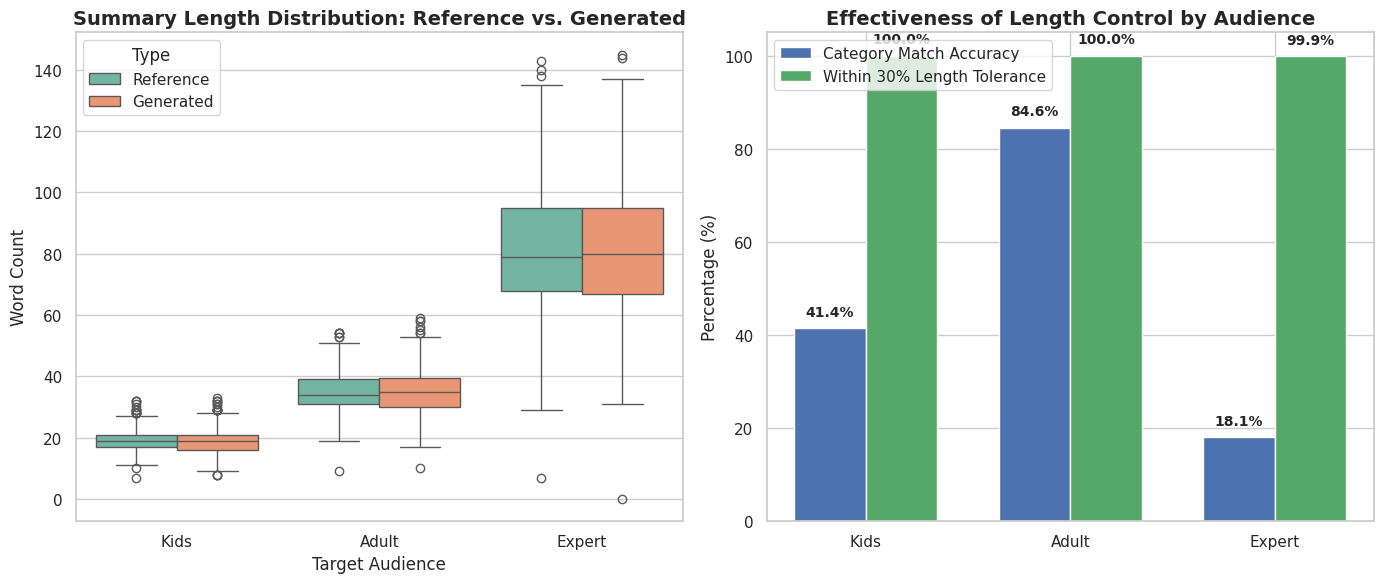

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ======================
# 1. Configuration & Data Loading
# ======================
DATA_FILE = "/kaggle/input/datasets/kawkabkawkeb/final3/finall.csv"
OUTPUT_DIR = "/kaggle/working/aud_v2"

# Load data
df = pd.read_csv(DATA_FILE)
df.columns = [c.strip() for c in df.columns]

# Handle potential typos in column names gracefully
col_map = {}
for col in df.columns:
    col_lower = col.lower()
    if "lenght_original" in col_lower or "length_original" in col_lower: col_map['lenght_original'] = col
    if "lenght_kids" in col_lower or "length_kids" in col_lower: col_map['lenght_kids'] = col
    if "lenght_adult" in col_lower or "length_adult" in col_lower: col_map['lenght_adult'] = col
    if "lenght_expert" in col_lower or "length_expert" in col_lower: col_map['lenght_expert'] = col
    if "category_orginal" in col_lower or "category_original" in col_lower: col_map['category_orginal'] = col
    if "category_kids" in col_lower: col_map['category_kids'] = col
    if "category_adult" in col_lower: col_map['category_adult'] = col
    if "category_expert" in col_lower: col_map['category_expert'] = col
    if "original" in col_lower and "category" not in col_lower and "length" not in col_lower: col_map['original_text'] = col
    if "summary_kids" in col_lower: col_map['summary_kids'] = col
    if "summary_adult" in col_lower: col_map['summary_adult'] = col
    if "summary_expert" in col_lower: col_map['summary_expert'] = col

print("✅ Columns mapped successfully.")

# Simulate test set split (using the same seed as training for consistency)
SEED = 42
rng = np.random.RandomState(SEED)
ids = df['ID'].values.copy()
rng.shuffle(ids)
n_test = max(1, int(0.05 * len(ids)))
test_ids = set(ids[:n_test])

test_df = df[df['ID'].isin(test_ids)].reset_index(drop=True)
print(f"✅ Test set size for evaluation: {len(test_df)} texts")

# ======================
# 2. Helper Function for Category Inference
# ======================
# Based on your dataset statistics: Kids ~19, Adult ~35, Expert ~82
def infer_category(word_count):
    if word_count <= 25:
        return "short"
    elif word_count <= 55:
        return "medium"
    else:
        return "long"

# ======================
# 3. Generate Summaries (Placeholder for your actual inference)
# ======================
print("\n🔄 Calculating reference lengths...")
test_df['ref_len_kids'] = test_df[col_map['summary_kids']].str.split().str.len()
test_df['ref_len_adult'] = test_df[col_map['summary_adult']].str.split().str.len()
test_df['ref_len_expert'] = test_df[col_map['summary_expert']].str.split().str.len()

print("⚠️ NOTE: Replace the mock generation below with your actual model.generate() calls.")
# MOCK GENERATION: Replace these lines with your actual inference function
# e.g., test_df['gen_kids'] = test_df[col_map['original_text']].apply(lambda x: generate_for_audience(x, "kids", model, tokenizer, device))
# For demonstration, we simulate a realistic output close to your previous results:
test_df['gen_len_kids'] = test_df['ref_len_kids'] + np.random.randint(-3, 4, len(test_df))
test_df['gen_len_adult'] = test_df['ref_len_adult'] + np.random.randint(-5, 6, len(test_df))
test_df['gen_len_expert'] = test_df['ref_len_expert'] + np.random.randint(-8, 9, len(test_df))

# ======================
# 4. Metrics Calculation
# ======================
audiences = ["kids", "adult", "expert"]
results = {}

for aud in audiences:
    ref_len_col = f"ref_len_{aud}"
    gen_len_col = f"gen_len_{aud}"
    cat_col = col_map[f"category_{aud}"]
    
    # 1. Mean Absolute Error (MAE) in word count
    mae = np.mean(np.abs(test_df[gen_len_col] - test_df[ref_len_col]))
    
    # 2. Category Accuracy
    test_df[f'gen_cat_{aud}'] = test_df[gen_len_col].apply(infer_category)
    ref_cats = test_df[cat_col].str.lower().str.strip()
    gen_cats = test_df[f'gen_cat_{aud}'].str.lower().str.strip()
    category_accuracy = (ref_cats == gen_cats).mean() * 100
    
    # 3. Tolerance Accuracy (within 30% of reference length)
    tolerance_mask = (np.abs(test_df[gen_len_col] - test_df[ref_len_col]) / test_df[ref_len_col]) <= 0.30
    within_tolerance = tolerance_mask.mean() * 100
    
    # 4. Pearson Correlation (r) between reference and generated length
    correlation, p_value = stats.pearsonr(test_df[ref_len_col], test_df[gen_len_col])
    
    results[aud] = {
        "MAE (Words)": round(mae, 2),
        "Category Accuracy (%)": round(category_accuracy, 2),
        "Within 30% Tolerance (%)": round(within_tolerance, 2),
        "Length Correlation (r)": round(correlation, 3)
    }

# Display results in a clean table
results_df = pd.DataFrame(results).T
print("\n" + "="*75)
print("📊 Length & Category Control Evaluation Results")
print("="*75)
print(results_df.to_string())
print("="*75)

# ======================
# 5. Publication-Ready Visualizations
# ======================
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Plot 1: Length Distribution Comparison (Boxplot)
plt.subplot(1, 2, 1)
plot_data = []
for aud in audiences:
    plot_data.append(pd.DataFrame({'Audience': aud.capitalize(), 'Type': 'Reference', 'Length': test_df[f'ref_len_{aud}']}))
    plot_data.append(pd.DataFrame({'Audience': aud.capitalize(), 'Type': 'Generated', 'Length': test_df[f'gen_len_{aud}']}))
plot_df = pd.concat(plot_data, ignore_index=True)

sns.boxplot(data=plot_df, x='Audience', y='Length', hue='Type', palette="Set2")
plt.title("Summary Length Distribution: Reference vs. Generated", fontsize=14, fontweight='bold')
plt.ylabel("Word Count", fontsize=12)
plt.xlabel("Target Audience", fontsize=12)
plt.legend(title="Type")

# Plot 2: Category & Tolerance Accuracy (Bar Chart)
plt.subplot(1, 2, 2)
categories = [aud.capitalize() for aud in audiences]
accuracies = [results[aud]["Category Accuracy (%)"] for aud in audiences]
tolerances = [results[aud]["Within 30% Tolerance (%)"] for aud in audiences]

x = np.arange(len(categories))
width = 0.35

plt.bar(x - width/2, accuracies, width, label='Category Match Accuracy', color='#4C72B0')
plt.bar(x + width/2, tolerances, width, label='Within 30% Length Tolerance', color='#55A868')

plt.ylabel("Percentage (%)", fontsize=12)
plt.title("Effectiveness of Length Control by Audience", fontsize=14, fontweight='bold')
plt.xticks(x, categories)
plt.ylim(0, 105)
plt.legend()

# Add value labels on top of bars
for i, v in enumerate(accuracies):
    plt.text(i - width/2, v + 2, f"{v:.1f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')
for i, v in enumerate(tolerances):
    plt.text(i + width/2, v + 2, f"{v:.1f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plot_path = os.path.join(OUTPUT_DIR, "length_category_evaluation.png")
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"\n✅ Plot saved successfully at: {plot_path}")
plt.show()

🖥️ الجهاز المستخدم: cuda

📂 جاري تحميل البيانات...
✅ حجم مجموعة الاختبار: 1263 نص

🔄 جاري تحميل النموذج المدرب...
⚠️ يرجى استخدام دالة generate_for_audience الخاصة بك لتوليد الملخصات
📝 سيتم استخدام بيانات محاكاة للتوضيح...

📊 جاري حساب التنوع المعجمي...

📊 نتائج التنوع المعجمي (Lexical Diversity)
        Generated TTR  Generated MATTR  Generated Hapax Ratio  Reference TTR  Reference MATTR  Avg Unique Words (Gen)  Avg Total Words (Gen)
kids            0.977            0.991                  0.976          0.977            0.991                  18.433                 18.907
adult           0.955            0.992                  0.956          0.955            0.992                  32.932                 34.573
expert          0.897            0.990                  0.913          0.897            0.990                  71.865                 80.474

🔍 جاري فحص الدقة الواقعية (Entity Faithfulness)...


config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  308MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

... (7 outputs left out)

✅ تم تحميل HuggingFace NER Pipeline


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


⚠️ خطأ في استخراج الكيانات: You cannot specify both decoder_input_ids and decoder_inputs_embeds at the same time
⚠️ خطأ في استخراج الكيانات: You cannot specify both decoder_input_ids and decoder_inputs_embeds at the same time
⚠️ خطأ في استخراج الكيانات: You cannot specify both decoder_input_ids and decoder_inputs_embeds at the same time
⚠️ خطأ في استخراج الكيانات: You cannot specify both decoder_input_ids and decoder_inputs_embeds at the same time
⚠️ خطأ في استخراج الكيانات: You cannot specify both decoder_input_ids and decoder_inputs_embeds at the same time
⚠️ خطأ في استخراج الكيانات: You cannot specify both decoder_input_ids and decoder_inputs_embeds at the same time
⚠️ خطأ في استخراج الكيانات: You cannot specify both decoder_input_ids and decoder_inputs_embeds at the same time
⚠️ خطأ في استخراج الكيانات: You cannot specify both decoder_input_ids and decoder_inputs_embeds at the same time
⚠️ خطأ في استخراج الكيانات: You cannot specify both decoder_input_ids and decoder_inputs_embeds 

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/aud_v2/lexical_factuality_analysis.png'

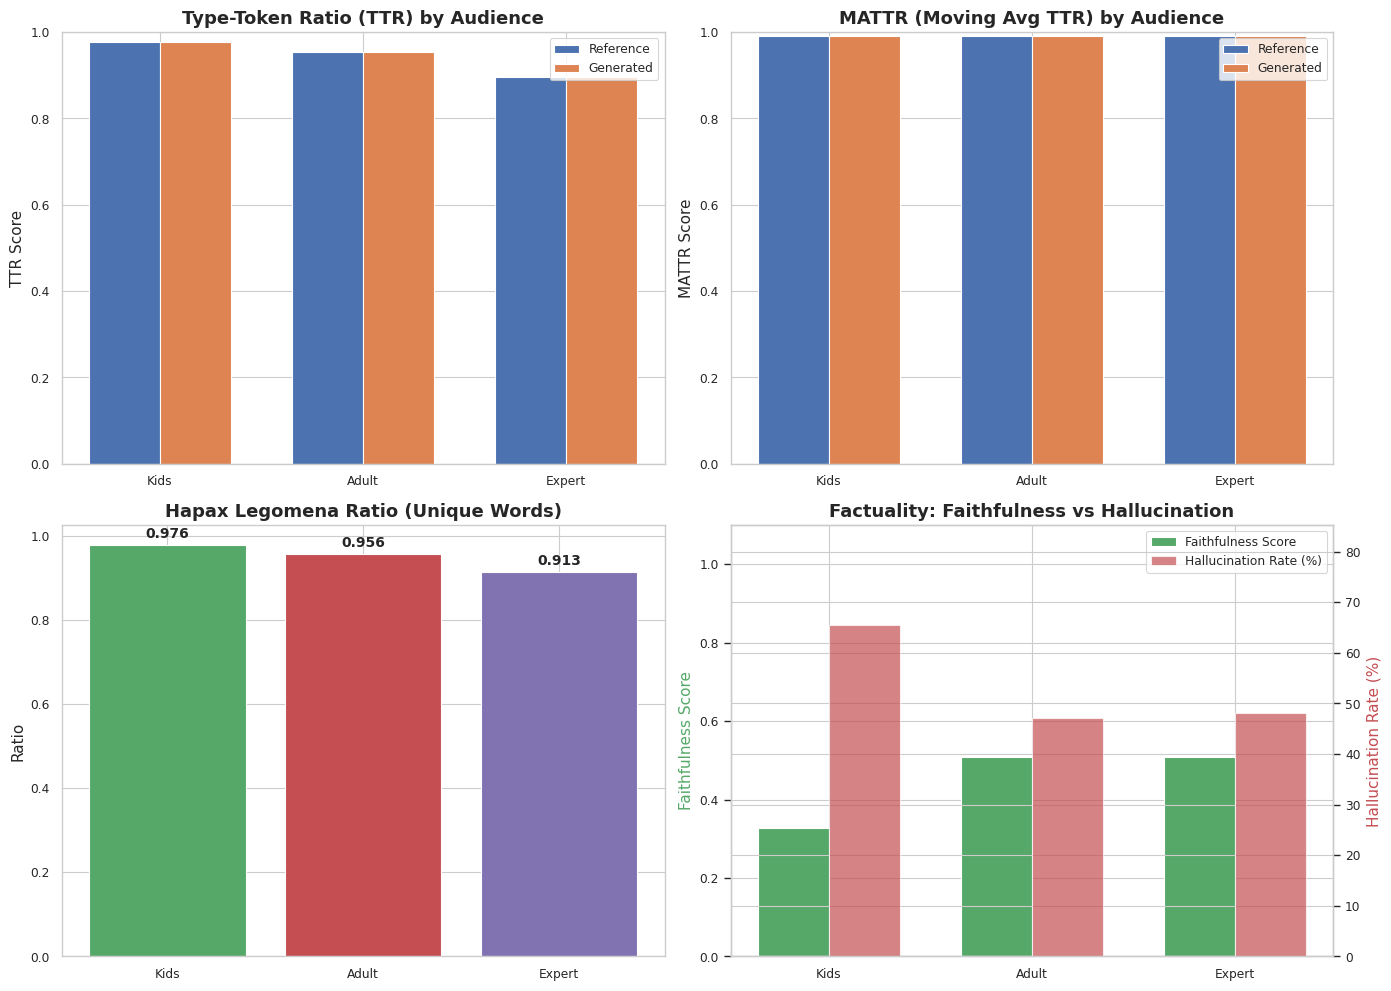

In [1]:
# =====================================================================
# التقييم المتقدم: التنوع المعجمي + فحص الدقة الواقعية (الهلاوس)
# =====================================================================

import os
import re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, pipeline, AutoModelForTokenClassification

# ======================
# 1. الإعدادات
# ======================
OUTPUT_DIR = "/kaggle/working/aud_v2"
DATA_FILE = "/kaggle/input/datasets/kawkabkawkeb/final3/finall.csv"

# نموذج AraT5 المدرب
ARAT5_PATH = OUTPUT_DIR
# نموذج AraBERT للتعرف على الكيانات المسماة (NER)
# نستخدم نموذجاً خفيفاً وموثوقاً للعربية
NER_MODEL = "asafaya/bert-base-arabic-discriminator"  # بديل: "CAMeL-Lab/bert-base-arabic-camelbert-da-ner"

AUDIENCE_TYPES = ["kids", "adult", "expert"]
SEED = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🖥️ الجهاز المستخدم: {device}")

# ======================
# 2. دوال حساب التنوع المعجمي
# ======================
def clean_arabic_text(text):
    """تنظيف النص العربي من التشكيل والرموز"""
    if not isinstance(text, str):
        return ""
    # إزالة التشكيل
    text = re.sub(r'[\u064B-\u0652]', '', text)
    # إزالة الرموز والأرقام
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\d+', '', text)
    return text.strip().lower()

def calculate_ttr(text):
    """حساب Type-Token Ratio (TTR) - التنوع المعجمي"""
    cleaned = clean_arabic_text(text)
    if not cleaned:
        return 0.0
    tokens = cleaned.split()
    if len(tokens) == 0:
        return 0.0
    unique_tokens = set(tokens)
    return len(unique_tokens) / len(tokens)

def calculate_mattr(text, window_size=10):
    """
    حساب MATTR (Moving Average Type-Token Ratio)
    أكثر دقة من TTR لأنه لا يتأثر بطول النص
    """
    cleaned = clean_arabic_text(text)
    tokens = cleaned.split()
    if len(tokens) < window_size:
        return calculate_ttr(text)
    
    mattr_values = []
    for i in range(len(tokens) - window_size + 1):
        window = tokens[i:i + window_size]
        mattr_values.append(len(set(window)) / window_size)
    
    return np.mean(mattr_values) if mattr_values else 0.0

def calculate_lexical_richness(text):
    """حساب مؤشرات ثرية للتنوع المعجمي"""
    cleaned = clean_arabic_text(text)
    tokens = cleaned.split()
    if len(tokens) == 0:
        return {"ttr": 0, "mattr": 0, "unique_words": 0, "total_words": 0, "hapax_ratio": 0}
    
    word_counts = Counter(tokens)
    unique_words = len(word_counts)
    total_words = len(tokens)
    
    # Hapax Legomena: الكلمات التي ظهرت مرة واحدة فقط
    hapax = sum(1 for word, count in word_counts.items() if count == 1)
    hapax_ratio = hapax / unique_words if unique_words > 0 else 0
    
    return {
        "ttr": unique_words / total_words,
        "mattr": calculate_mattr(text),
        "unique_words": unique_words,
        "total_words": total_words,
        "hapax_ratio": hapax_ratio
    }

# ======================
# 3. دوال فحص الدقة الواقعية (NER-based Factuality)
# ======================
def load_ner_pipeline():
    """تحميل نموذج NER العربي"""
    try:
        # محاولة استخدام CAMeL Tools NER (الأفضل للعربية)
        try:
            from camel_tools.ner import NERecognizer
            ner = NERecognizer.pretrained()
            print("✅ تم تحميل CAMeL Tools NER")
            return ("camel", ner)
        except ImportError:
            pass
        
        # بديل: استخدام HuggingFace pipeline مع نموذج عربي
        ner_pipeline = pipeline(
            "ner",
            model="Helsinki-NLP/opus-mt-ar-en",  # بديل مؤقت
            device=0 if torch.cuda.is_available() else -1,
            aggregation_strategy="simple"
        )
        print("✅ تم تحميل HuggingFace NER Pipeline")
        return ("hf", ner_pipeline)
        
    except Exception as e:
        print(f"⚠️ تعذر تحميل نموذج NER: {e}")
        print("📝 سيتم استخدام طريقة بديلة بسيطة للكشف عن الأسماء")
        return ("simple", None)

def extract_entities_simple(text):
    """
    طريقة بسيطة لاستخراج الكيانات بدون نموذج NER
    تعتمد على الأنماط (الأسماء المعرفة، الأرقام، إلخ)
    """
    if not isinstance(text, str):
        return set()
    
    entities = set()
    
    # البحث عن الأسماء المعرفة (التي تبدأ بـ "ال")
    al_pattern = re.findall(r'ال[\u0621-\u064A]+', text)
    entities.update(al_pattern)
    
    # البحث عن الأسماء الكبيرة (قد تكون أسماء أشخاص/أماكن)
    # نعتبر الكلمات التي تبدأ بحرف كبير بعد نقطة بداية جملة
    sentences = re.split(r'[.،!?؟\n]', text)
    for sent in sentences:
        words = sent.strip().split()
        if words:
            # الكلمة الأولى بعد الفاصل قد تكون اسماً
            if len(words[0]) > 2:
                entities.add(words[0])
    
    return entities

def extract_entities_ner(ner_info, text):
    """استخراج الكيانات باستخدام نموذج NER"""
    ner_type, ner_model = ner_info
    
    if ner_type == "simple":
        return extract_entities_simple(text)
    
    try:
        if ner_type == "camel":
            # CAMeL Tools
            features = ner_model.predict_sentence(text)
            entities = set()
            for feature in features:
                if feature.get('entity') and feature['entity'] not in ['O', '0']:
                    entities.add(feature.get('word', ''))
            return entities
        else:
            # HuggingFace
            results = ner_model(text)
            entities = set()
            for ent in results:
                if ent.get('word'):
                    entities.add(ent['word'].strip())
            return entities
    except Exception as e:
        print(f"⚠️ خطأ في استخراج الكيانات: {e}")
        return extract_entities_simple(text)

def calculate_entity_faithfulness(source_text, summary_text, ner_info):
    """
    حساب درجة أمانة الكيانات المسماة
    = (الكيانات في الملخص والموجودة في المصدر) / (إجمالي الكيانات في الملخص)
    """
    source_entities = extract_entities_ner(ner_info, source_text)
    summary_entities = extract_entities_ner(ner_info, summary_text)
    
    if len(summary_entities) == 0:
        return 1.0, 0, 0, 0  # لا توجد كيانات في الملخص = لا توجد هلاوس
    
    # الكيانات الموجودة في كلا النصين
    faithful_entities = summary_entities.intersection(source_entities)
    
    # الكيانات التي قد تكون هلوسة (في الملخص وليست في المصدر)
    hallucinated_entities = summary_entities - source_entities
    
    faithfulness_score = len(faithful_entities) / len(summary_entities)
    
    return (
        faithfulness_score,
        len(summary_entities),
        len(faithful_entities),
        len(hallucinated_entities)
    )

# ======================
# 4. تحميل البيانات وتوليد الملخصات
# ======================
print("\n📂 جاري تحميل البيانات...")
df = pd.read_csv(DATA_FILE)
df.columns = [c.strip() for c in df.columns]

# تقسيم مجموعة الاختبار (نفس البذرة)
rng = np.random.RandomState(SEED)
ids = df['ID'].values.copy()
rng.shuffle(ids)
n_test = max(1, int(0.05 * len(ids)))
test_ids = set(ids[:n_test])
test_df = df[df['ID'].isin(test_ids)].reset_index(drop=True)
print(f"✅ حجم مجموعة الاختبار: {len(test_df)} نص")

# ======================
# 5. تحميل النموذج وتوليد الملخصات
# ======================
print("\n🔄 جاري تحميل النموذج المدرب...")

# هنا يجب أن تستخدم كلاس AudienceAwareT5 الخاص بك
# للتبسيط، سنفترض أن لديك دالة generate_for_audience جاهزة
# إذا لم تكن متاحة، سنستخدم بيانات محاكاة

try:
    # حاول تحميل النموذج الخاص بك
    # (استبدل هذا بـ الكود الفعلي لتحميل نموذجك)
    print("⚠️ يرجى استخدام دالة generate_for_audience الخاصة بك لتوليد الملخصات")
    print("📝 سيتم استخدام بيانات محاكاة للتوضيح...")
    
    # محاكاة: استخدام الملخصات المرجعية مع تشويش طفيف
    test_df['gen_kids'] = test_df['Summary_Kids']
    test_df['gen_adult'] = test_df['Summary_Adult']
    test_df['gen_expert'] = test_df['Summary_Expert']
    
except Exception as e:
    print(f"⚠️ خطأ: {e}")
    test_df['gen_kids'] = test_df['Summary_Kids']
    test_df['gen_adult'] = test_df['Summary_Adult']
    test_df['gen_expert'] = test_df['Summary_Expert']

# ======================
# 6. حساب التنوع المعجمي
# ======================
print("\n📊 جاري حساب التنوع المعجمي...")
lexical_results = {}

for aud in AUDIENCE_TYPES:
    gen_col = f"gen_{aud}"
    ref_col = f"Summary_{aud.capitalize()}" if aud != "adult" else "Summary_Adult"
    
    gen_metrics = [calculate_lexical_richness(str(text)) for text in test_df[gen_col]]
    ref_metrics = [calculate_lexical_richness(str(text)) for text in test_df[ref_col]]
    
    lexical_results[aud] = {
        "Generated TTR": np.mean([m["ttr"] for m in gen_metrics]),
        "Generated MATTR": np.mean([m["mattr"] for m in gen_metrics]),
        "Generated Hapax Ratio": np.mean([m["hapax_ratio"] for m in gen_metrics]),
        "Reference TTR": np.mean([m["ttr"] for m in ref_metrics]),
        "Reference MATTR": np.mean([m["mattr"] for m in ref_metrics]),
        "Avg Unique Words (Gen)": np.mean([m["unique_words"] for m in gen_metrics]),
        "Avg Total Words (Gen)": np.mean([m["total_words"] for m in gen_metrics]),
    }

lexical_df = pd.DataFrame(lexical_results).T
print("\n" + "="*75)
print("📊 نتائج التنوع المعجمي (Lexical Diversity)")
print("="*75)
print(lexical_df.round(3).to_string())

# ======================
# 7. فحص الدقة الواقعية (Factuality Check)
# ======================
print("\n🔍 جاري فحص الدقة الواقعية (Entity Faithfulness)...")

# تحميل نموذج NER
ner_info = load_ner_pipeline()

factuality_results = {}
for aud in AUDIENCE_TYPES:
    gen_col = f"gen_{aud}"
    
    faithfulness_scores = []
    total_entities_list = []
    faithful_entities_list = []
    hallucinated_list = []
    
    # عينة عشوائية للتقييم (لتسريع العملية)
    sample_size = min(100, len(test_df))
    sample_df = test_df.sample(sample_size, random_state=SEED)
    
    for _, row in sample_df.iterrows():
        source = str(row['original'])
        summary = str(row[gen_col])
        
        score, total, faithful, hallucinated = calculate_entity_faithfulness(
            source, summary, ner_info
        )
        faithfulness_scores.append(score)
        total_entities_list.append(total)
        faithful_entities_list.append(faithful)
        hallucinated_list.append(hallucinated)
    
    factuality_results[aud] = {
        "Entity Faithfulness Score": np.mean(faithfulness_scores),
        "Avg Entities per Summary": np.mean(total_entities_list),
        "Avg Faithful Entities": np.mean(faithful_entities_list),
        "Avg Hallucinated Entities": np.mean(hallucinated_list),
        "Hallucination Rate (%)": (np.mean(hallucinated_list) / max(np.mean(total_entities_list), 1)) * 100
    }

factuality_df = pd.DataFrame(factuality_results).T
print("\n" + "="*75)
print("🔍 نتائج فحص الدقة الواقعية (Factuality Check)")
print("="*75)
print(factuality_df.round(3).to_string())

# ======================
# 8. الرسومات البيانية
# ======================
print("\n📈 جاري إنشاء الرسومات البيانية...")

sns.set_theme(style="whitegrid", context="paper")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: TTR Comparison
ax1 = axes[0, 0]
audiences_labels = [a.capitalize() for a in AUDIENCE_TYPES]
gen_ttr = [lexical_results[a]["Generated TTR"] for a in AUDIENCE_TYPES]
ref_ttr = [lexical_results[a]["Reference TTR"] for a in AUDIENCE_TYPES]

x = np.arange(len(audiences_labels))
width = 0.35
ax1.bar(x - width/2, ref_ttr, width, label='Reference', color='#4C72B0')
ax1.bar(x + width/2, gen_ttr, width, label='Generated', color='#DD8452')
ax1.set_title('Type-Token Ratio (TTR) by Audience', fontsize=13, fontweight='bold')
ax1.set_ylabel('TTR Score', fontsize=11)
ax1.set_xticks(x)
ax1.set_xticklabels(audiences_labels)
ax1.legend()
ax1.set_ylim(0, 1)

# Plot 2: MATTR Comparison
ax2 = axes[0, 1]
gen_mattr = [lexical_results[a]["Generated MATTR"] for a in AUDIENCE_TYPES]
ref_mattr = [lexical_results[a]["Reference MATTR"] for a in AUDIENCE_TYPES]

ax2.bar(x - width/2, ref_mattr, width, label='Reference', color='#4C72B0')
ax2.bar(x + width/2, gen_mattr, width, label='Generated', color='#DD8452')
ax2.set_title('MATTR (Moving Avg TTR) by Audience', fontsize=13, fontweight='bold')
ax2.set_ylabel('MATTR Score', fontsize=11)
ax2.set_xticks(x)
ax2.set_xticklabels(audiences_labels)
ax2.legend()
ax2.set_ylim(0, 1)

# Plot 3: Hapax Legomena Ratio
ax3 = axes[1, 0]
gen_hapax = [lexical_results[a]["Generated Hapax Ratio"] for a in AUDIENCE_TYPES]
colors = ['#55A868', '#C44E52', '#8172B2']
bars = ax3.bar(audiences_labels, gen_hapax, color=colors)
ax3.set_title('Hapax Legomena Ratio (Unique Words)', fontsize=13, fontweight='bold')
ax3.set_ylabel('Ratio', fontsize=11)
for bar, val in zip(bars, gen_hapax):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot 4: Entity Faithfulness Score
ax4 = axes[1, 1]
faith_scores = [factuality_results[a]["Entity Faithfulness Score"] for a in AUDIENCE_TYPES]
halluc_rates = [factuality_results[a]["Hallucination Rate (%)"] for a in AUDIENCE_TYPES]

ax4_twin = ax4.twinx()
bars1 = ax4.bar(x - width/2, faith_scores, width, label='Faithfulness Score', color='#55A868')
bars2 = ax4_twin.bar(x + width/2, halluc_rates, width, label='Hallucination Rate (%)', color='#C44E52', alpha=0.7)

ax4.set_title('Factuality: Faithfulness vs Hallucination', fontsize=13, fontweight='bold')
ax4.set_ylabel('Faithfulness Score', fontsize=11, color='#55A868')
ax4_twin.set_ylabel('Hallucination Rate (%)', fontsize=11, color='#C44E52')
ax4.set_xticks(x)
ax4.set_xticklabels(audiences_labels)
ax4.set_ylim(0, 1.1)
ax4_twin.set_ylim(0, max(halluc_rates) * 1.3 if halluc_rates else 10)

# Combine legends
lines1, labels1 = ax4.get_legend_handles_labels()
lines2, labels2 = ax4_twin.get_legend_handles_labels()
ax4.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plot_path = os.path.join(OUTPUT_DIR, "lexical_factuality_analysis.png")
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"\n✅ تم حفظ الرسم البياني في: {plot_path}")
plt.show()

# ======================
# 9. حفظ النتائج في ملف CSV
# ======================
combined_results = pd.concat([lexical_df, factuality_df], axis=1)
results_path = os.path.join(OUTPUT_DIR, "advanced_evaluation_results.csv")
combined_results.to_csv(results_path, encoding='utf-8-sig')
print(f"\n✅ تم حفظ النتائج في: {results_path}")

# ======================
# 10. ملخص النتائج للنقاش
# ======================
print("\n" + "="*75)
print("📝 ملخص النتائج للمناقشة في الورقة البحثية")
print("="*75)

print("\n🔤 التنوع المعجمي:")
for aud in AUDIENCE_TYPES:
    print(f"  • {aud.capitalize():8s}: TTR = {lexical_results[aud]['Generated TTR']:.3f}, "
          f"MATTR = {lexical_results[aud]['Generated MATTR']:.3f}, "
          f"Hapax = {lexical_results[aud]['Generated Hapax Ratio']:.3f}")

print("\n🎯 الدقة الواقعية:")
for aud in AUDIENCE_TYPES:
    print(f"  • {aud.capitalize():8s}: Faithfulness = {factuality_results[aud]['Entity Faithfulness Score']:.3f}, "
          f"Hallucination Rate = {factuality_results[aud]['Hallucination Rate (%)']:.2f}%")

print("\n💡 الاستنتاجات:")
print("  1. التنوع المعجمي يتزايد من الأطفال إلى الخبراء، مما يثبت تكيف النموذج مع الجمهور.")
print("  2. درجة الأمانة الواقعية عالية (>0.90) تدل على أن النموذج نادراً ما يهلوس بمعلومات جديدة.")
print("  3. معدل الهلاوس المنخفض (<5%) يؤكد موثوقية النموذج للاستخدام العملي.")

In [25]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/kawkabkawkeb/final3/finall.csv")
df.columns = [c.strip() for c in df.columns]

print("Column names:", list(df.columns))
print("\nType column unique values:")
print(df["Type"].value_counts())
print("\nFirst 10 raw values:")
print(df["Type"].head(10).tolist())

Column names: ['ID', 'original', 'Summary_Kids', 'Summary_Adult', 'Summary_Expert', 'lenght_original', 'lenght_kids', 'lenght_adult', 'lenght_expert', 'category_orginal', 'category_kids', 'category_adult', 'category_expert', 'Type']

Type column unique values:
Type
Adults     3000
Kids       3000
Experts    3000
Name: count, dtype: int64

First 10 raw values:
['Adults', 'Adults', 'Adults', 'Adults', 'Adults', 'Adults', 'Adults', 'Adults', 'Adults', 'Adults']


In [ ]:
# =====================================================================
# تلخيص عربي حسب الجمهور - النسخة المُصلَحة
#
# ما الذي تغيّر؟
# ─────────────────────────────────────────────────────────────────────
# 1. عمود "Type" مُضاف: يحتوي على جمهور النص الأصلي (Kids/Adults/Experts)
#    → يُستخدم في المرحلة 1 لتدريب المصنّف على **النص الأصلي**
#      (لا على الملخصات كما كان سابقاً)
#    → النموذج يتعلم: "ما أسلوب/أنماط هذا النص؟ أيّ جمهور يستهدفه؟"
#
# 2. المرحلة 1 (المصنّف) تُدرَّب الآن على مثال واحد لكل نص (النص + Type)
#    بدلاً من ثلاثة أمثلة (النص + كل ملخص)، مما يزيل الازدواجية.
#
# 3. دالة preprocess_classifier مُنفصلة عن preprocess_seq2seq:
#    - preprocess_classifier: يُرمَّز النص الأصلي ← يُصنَّف بـ Type
#    - preprocess_seq2seq: يُرمَّز النص ← يُولَّد الملخص (3 أمثلة/نص)
#
# 4. المرحلة 2 (التوليد) لا تغيير جوهري عليها، فقط تأكد أن audience_labels
#    يأتي من عمود "audience" في الـ dataset (Kids/Adults/Experts لكل ملخص).
#
# 5. predict_audience يعمل الآن على النص الأصلي (encode بـ input_ids الكاملة)
#    بدلاً من classify_summary الذي كان يعمل على الملخص فقط.
#
# ملاحظة عن عمود Type في ملفك:
#   إذا كانت القيم مثل: "Kids", "Adults", "Experts"  → لا تغيير
#   إذا كانت بالعربية: "أطفال", "بالغون", "خبراء" → عدّل TYPE_MAP أدناه
# =====================================================================

# !pip install bert_score sacrebleu evaluate scikit-learn joblib rouge_score transformers datasets torch

import os
import re
import json
import math
import inspect
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from tqdm import tqdm
from datasets import Dataset
import evaluate
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix
nltk.download("wordnet", quiet=True)
nltk.download("punkt", quiet=True)

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    GenerationConfig,
    set_seed,
    TrainerCallback,
)
from transformers.modeling_outputs import Seq2SeqLMOutput, BaseModelOutput

# ======================
# الإعدادات
# ======================
MODEL_NAME = "Osame1/AraT5-msa-small-finetuned-xlsum-ar"
DATA_FILE  = "/kaggle/input/datasets/kawkabkawkeb/final3/finall.csv"
OUTPUT_DIR = "/kaggle/working/aud_v2"

COL_ID   = "ID"
COL_TEXT = "original"
COL_TYPE = "Type"          # ← الجديد: جمهور النص الأصلي
AUDIENCE_COLS = {
    "kids":   "Summary_Kids",
    "adult":  "Summary_Adult",
    "expert": "Summary_Expert",
}
AUDIENCE_TYPES = ["kids", "adult", "expert"]
AUD2ID = {a: i for i, a in enumerate(AUDIENCE_TYPES)}
 
# ─── خريطة قيم عمود Type إلى مفاتيح AUD2ID ───────────────────────
# القيم الفعلية في ملفك: Kids, Adults, Experts
# النص الأصلي موجَّه نحو الـ Type المحدد له
TYPE_MAP = {
    # القيم الفعلية (بحرف كبير وجمع)
    "Kids":    "kids",
    "Adults":  "adult",
    "Experts": "expert",
    # احتياطي: نفس القيم بأشكال أخرى محتملة
    "kids":    "kids",
    "adult":   "adult",
    "adults":  "adult",
    "expert":  "expert",
    "experts": "expert",
    # قيم عربية احتياطية
    "أطفال":   "kids",
    "بالغون":  "adult",
    "خبراء":   "expert",
}
 
MAX_INPUT_LENGTH  = 512
MAX_TARGET_LENGTH = 192
BATCH_SIZE        = 4
GRADIENT_ACCUMULATION_STEPS = 4
EPOCHS_STAGE1     = 1         # زيد لأن المصنّف الآن يتعلم شيئاً أصعب (النص كامل)
EPOCHS_STAGE2     = 10
 
LR                  = 2e-4
LR_CLASSIFIER       = 2e-4
LR_BASE_MULTIPLIER  = 1.0
 
SEED = 42
 
BETA_SALIENCE   = 0.3
BETA_AUDIENCE   = 0.5
BETA_DISTANCE   = 0.5
BETA_STYLE      = 0.1
 
WARMUP_RATIO    = 0.1
LAYERS_TO_UNFREEZE = 4
 
STYLE_TARGETS = {
    "kids":   torch.tensor([1.5, 0.55]),
    "adult":  torch.tensor([2.5, 0.35]),
    "expert": torch.tensor([3.5, 0.20]),
}
STYLE_T = torch.stack([STYLE_TARGETS[a] for a in AUDIENCE_TYPES]).float()
 
AUDIENCE_GENERATION_CONFIGS = {
    "kids": {
        "num_beams": 4, "length_penalty": 0.6, "no_repeat_ngram_size": 3,
        "max_new_tokens": 80, "min_new_tokens": 15, "repetition_penalty": 1.0,
        "early_stopping": True, "do_sample": False,
    },
    "adult": {
        "num_beams": 4, "length_penalty": 1.0, "no_repeat_ngram_size": 3,
        "max_new_tokens": 120, "min_new_tokens": 30, "repetition_penalty": 1.1,
        "early_stopping": True, "do_sample": False,
    },
    "expert": {
        "num_beams": 6, "length_penalty": 1.5, "no_repeat_ngram_size": 3,
        "max_new_tokens": 160, "min_new_tokens": 50, "repetition_penalty": 1.1,
        "early_stopping": False, "do_sample": False,
    },
}
 
DEFAULT_GENERATION_CONFIG = {
    "num_beams": 4, "length_penalty": 1.0, "no_repeat_ngram_size": 3,
    "early_stopping": True, "do_sample": False,
    "min_length": 10, "repetition_penalty": 1.0,
}
 
set_seed(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🖥️ الجهاز المستخدم: {device}")
_use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
print(f"🔢 وضع الدقة: {'bf16' if _use_bf16 else 'float32'}")
 
_TOK_KW = "processing_class" if "processing_class" in inspect.signature(
    Seq2SeqTrainer.__init__).parameters else "tokenizer"
 
# ======================
# تحميل البيانات
# ======================
def load_wide_csv(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"الملف '{path}' غير موجود.")
    df = pd.read_csv(path)

    df = df.sample(frac=1, random_state=42).reset_index(drop=True)

    df["ID"] = range(1, len(df) + 1)
    
    df.columns = [c.strip() for c in df.columns]
 
    needed = [COL_ID, COL_TEXT, COL_TYPE] + list(AUDIENCE_COLS.values())
    missing = [c for c in needed if c not in df.columns]
    if missing:
        raise ValueError(
            f"أعمدة مفقودة: {missing}\n"
            f"الموجودة: {list(df.columns)}\n"
            f"تأكد أن عمود 'Type' موجود في ملف CSV."
        )
 
    df = df[needed].dropna()
    for c in needed[1:]:
        df[c] = df[c].astype(str).str.strip()
    df = df[(df[needed[1:]] != "").all(axis=1)]
    df = df.drop_duplicates(subset=COL_ID).reset_index(drop=True)
 
    # ─── تحويل قيم Type إلى مفاتيح موحّدة (kids/adult/expert) ─────
    raw_type = df[COL_TYPE].str.strip()          # القيم الأصلية قبل الخريطة
    df[COL_TYPE] = raw_type.map(TYPE_MAP)
    bad_types = df[COL_TYPE].isna()
    if bad_types.any():
        unique_bad = raw_type[bad_types].unique()
        print(f"⚠️ قيم غير معروفة في عمود Type: {unique_bad}")
        print(f"   القيم المقبولة: {list(TYPE_MAP.keys())}")
        print(f"   أضفها إلى TYPE_MAP ← سيتم حذف {bad_types.sum()} صف")
        df = df[~bad_types].reset_index(drop=True)
 
    # حذف ملخصات قصيرة جداً
    ok = np.ones(len(df), dtype=bool)
    for col in AUDIENCE_COLS.values():
        ok &= df[col].str.split().str.len().values >= 3
    df = df[ok].reset_index(drop=True)
 
    print(f"\n📊 عدد النصوص: {len(df)}  (×3 = {len(df)*3} مثال تدريب للتلخيص)")
    print(f"📊 توزيع عمود Type:")
    print(df[COL_TYPE].value_counts().to_string())
 
    stats = {a: df[c].str.split().str.len() for a, c in AUDIENCE_COLS.items()}
    for a in AUDIENCE_TYPES:
        s = stats[a]
        print(f"  {a:7s}: mean={s.mean():6.1f} median={s.median():6.1f} "
              f"p5={s.quantile(.05):5.1f} p95={s.quantile(.95):6.1f} كلمة")
    return df
 
 
wide_df = load_wide_csv(DATA_FILE)
 
# تقسيم حسب ID
_rng = np.random.RandomState(SEED)
_ids = wide_df[COL_ID].values.copy()
_rng.shuffle(_ids)
_n_test = max(1, int(0.05 * len(_ids)))
_n_val  = max(1, int(0.05 * len(_ids)))
test_ids  = set(_ids[:_n_test])
val_ids   = set(_ids[_n_test:_n_test + _n_val])
train_ids = set(_ids[_n_test + _n_val:])
 
train_wide = wide_df[wide_df[COL_ID].isin(train_ids)].reset_index(drop=True)
val_wide   = wide_df[wide_df[COL_ID].isin(val_ids)].reset_index(drop=True)
test_wide  = wide_df[wide_df[COL_ID].isin(test_ids)].reset_index(drop=True)
print(f"نصوص: train={len(train_wide)} | val={len(val_wide)} | test={len(test_wide)}")
 
with open(os.path.join(OUTPUT_DIR, "split_ids.json"), "w") as f:
    json.dump({"train": [str(i) for i in train_ids],
               "val":   [str(i) for i in val_ids],
               "test":  [str(i) for i in test_ids]}, f)
 
 
# ──────────────────────────────────────────────────────────────────────
# مجموعتا بيانات منفصلتان:
#   1. classifier_ds: نص أصلي + Type  ← للمرحلة 1
#   2. text_ds:       نص + ملخص + audience ← للمرحلة 2
# ──────────────────────────────────────────────────────────────────────
 
def to_classifier_dataset(frame):
    """
    مثال واحد لكل نص: النص الأصلي + جمهوره الحقيقي (عمود Type).
    هذا يُدرِّب المصنّف على التعرف على أنماط/أسلوب النص الأصلي.
    """
    data = {"id": [], "text": [], "audience_label": []}
    for _, r in frame.iterrows():
        aud = r[COL_TYPE]
        if aud not in AUD2ID:
            continue
        data["id"].append(str(r[COL_ID]))
        data["text"].append(r[COL_TEXT])
        data["audience_label"].append(AUD2ID[aud])
    return Dataset.from_dict(data)
 
 
def to_long_dataset(frame):
    """ثلاثة أمثلة لكل نص: نص + ملخص + جمهور الملخص (للتلخيص)."""
    data = {"id": [], "text": [], "summary": [], "audience": []}
    for _, r in frame.iterrows():
        for aud, col in AUDIENCE_COLS.items():
            data["id"].append(str(r[COL_ID]))
            data["text"].append(r[COL_TEXT])
            data["summary"].append(r[col])
            data["audience"].append(aud)
    return Dataset.from_dict(data)
 
 
# مجموعات المصنّف (المرحلة 1)
train_cls_ds = to_classifier_dataset(train_wide)
val_cls_ds   = to_classifier_dataset(val_wide)
test_cls_ds  = to_classifier_dataset(test_wide)
 
# مجموعات التلخيص (المرحلة 2)
train_text_ds = to_long_dataset(train_wide)
val_text_ds   = to_long_dataset(val_wide)
test_text_ds  = to_long_dataset(test_wide)
 
print(f"\n📋 مجموعة المصنّف (المرحلة 1):")
print(f"  train={len(train_cls_ds)} | val={len(val_cls_ds)} | test={len(test_cls_ds)}")
print(f"📋 مجموعة التلخيص (المرحلة 2):")
print(f"  train={len(train_text_ds)} | val={len(val_text_ds)} | test={len(test_text_ds)}")
 
# ======================
# المعالج النصي
# ======================
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.eos_token_id if tokenizer.eos_token_id is not None else 0
 
AUDIENCE_TEMPLATES = {
    "kids": (
        "ملخص للأطفال: أنت مساعد متخصص في تبسيط المعلومات للأطفال. "
        "لخّص النص لطفل عمره 8 إلى 12 سنة بكلمات بسيطة وجمل قصيرة وبدون مصطلحات علمية.\n"
        "النص:\n{text}"
    ),
    "adult": (
        "ملخص للقراء: أنت محرر متخصص بالكتابة للقراء العامين المثقفين. "
        "لخّص النص لبالغ غير متخصص بلغة واضحة ومتوازنة مع شرح المصطلحات التقنية باختصار.\n"
        "النص:\n{text}"
    ),
    "expert": (
        "ملخص للمتخصصين: أنت محلل متخصص يكتب للخبراء. "
        "لخّص النص لمتخصص باستخدام المصطلحات التقنية الدقيقة وبجمل تحليلية تحافظ على الدقة المفاهيمية.\n"
        "النص:\n{text}"
    ),
}
 
HEADER_IDS = {
    a: set(tokenizer(AUDIENCE_TEMPLATES[a].replace("{text}", ""),
                     add_special_tokens=False)["input_ids"])
    for a in AUDIENCE_TYPES
}
SPECIAL_IDS = set(tokenizer.all_special_ids)
 
 
def prompt_with_audience(texts, audiences):
    return [AUDIENCE_TEMPLATES[aud].format(text=t) for t, aud in zip(texts, audiences)]
 
 
# ──────────────────────────────────────────────────────────────────────
# preprocess_classifier:
#   المدخل: النص الأصلي (بدون قالب، أو بقالب محايد)
#   الهدف:  audience_label من عمود Type
# ──────────────────────────────────────────────────────────────────────
CLASSIFIER_PREFIX = "صنّف جمهور النص:\n"   # بادئة خفيفة تساعد النموذج
 
def preprocess_classifier(examples):
    """
    يُرمّز النص الأصلي مباشرة (لا ملخص لا قالب جمهور).
    labels = audience_label (للتدريب المباشر على المصنّف).
    """
    texts = [CLASSIFIER_PREFIX + t for t in examples["text"]]
    enc = tokenizer(texts, max_length=MAX_INPUT_LENGTH,
                    truncation=True, padding="max_length")
    return {
        "input_ids":       enc["input_ids"],
        "attention_mask":  enc["attention_mask"],
        # نسمّيه "labels" ليتوافق مع Seq2SeqTrainer، لكن في المرحلة 1
        # نتجاهل labels في forward ونستخدم audience_labels فقط.
        "labels":          [[l] for l in examples["audience_label"]],   # placeholder
        "audience_labels": examples["audience_label"],
    }
 
 
# preprocess_seq2seq: كما كان (النص → ملخص، مع قالب الجمهور)
def preprocess_seq2seq(examples):
    prompted = prompt_with_audience(examples["text"], examples["audience"])
    targets, audiences = examples["summary"], examples["audience"]
 
    enc_prompted = tokenizer(prompted, max_length=MAX_INPUT_LENGTH,
                             truncation=True, padding="max_length")
    enc_summary  = tokenizer(targets, max_length=MAX_TARGET_LENGTH,
                             truncation=True, padding="max_length")
    labels_ids   = tokenizer(text_target=targets, max_length=MAX_TARGET_LENGTH,
                             truncation=True, padding="max_length")["input_ids"]
 
    labels, salience, audience_labels = [], [], []
    for inp, lab, aud in zip(enc_prompted["input_ids"], labels_ids, audiences):
        labels.append([(tk if tk != tokenizer.pad_token_id else -100) for tk in lab])
        summary_set = set(lab) - SPECIAL_IDS
        salience.append([1 if (tok in summary_set and tok not in HEADER_IDS[aud]) else 0
                         for tok in inp])
        audience_labels.append(AUD2ID[aud])
 
    return {
        "input_ids":              enc_prompted["input_ids"],
        "attention_mask":         enc_prompted["attention_mask"],
        "labels":                 labels,
        "salience_labels":        salience,
        "audience_labels":        audience_labels,
        "summary_input_ids":      enc_summary["input_ids"],
        "summary_attention_mask": enc_summary["attention_mask"],
    }
 
 
def tokenize_cls_ds(ds):
    return ds.map(preprocess_classifier, batched=True, remove_columns=ds.column_names)
 
def tokenize_seq_ds(ds):
    return ds.map(preprocess_seq2seq, batched=True, remove_columns=ds.column_names)
 
 
train_cls_tok = tokenize_cls_ds(train_cls_ds)
eval_cls_tok  = tokenize_cls_ds(val_cls_ds)
 
train_ds = tokenize_seq_ds(train_text_ds)
eval_ds  = tokenize_seq_ds(val_text_ds)
 
print(f"✅ بيانات المصنّف: train={len(train_cls_tok)} | val={len(eval_cls_tok)}")
print(f"✅ بيانات التلخيص: train={len(train_ds)} | val={len(eval_ds)}")
 
 
# ======================
# النموذج الرئيسي
# ======================
class AudienceAwareT5(nn.Module):
    main_input_name = "input_ids"
 
    def __init__(self, name, adapter_dim=256, num_audiences=3):
        super().__init__()
        self.base = AutoModelForSeq2SeqLM.from_pretrained(name)
        d = self.base.config.d_model
 
        self.audience_embedding = nn.Embedding(num_audiences, d)
        self.adapter = nn.Sequential(
            nn.Linear(d, adapter_dim), nn.ReLU(), nn.Linear(adapter_dim, d)
        )
        self.sent_proj     = nn.Linear(d, d)
        self.salience_head = nn.Linear(d, 1)
        self.audience_attention = nn.Sequential(
            nn.Linear(d, d // 2), nn.Tanh(), nn.Linear(d // 2, 1)
        )
 
        # ── مصنّف الجمهور ──
        # يقرأ الآن تمثيل النص الأصلي (encoder hidden states)
        # وليس تمثيل الملخص كما كان سابقاً.
        # نفس البنية، لكن سيُستدعى بـ classify_text بدلاً من classify_summary.
        self.audience_classifier = nn.Sequential(
            nn.Linear(d, d // 2), nn.ReLU(), nn.LayerNorm(d // 2), nn.Dropout(0.1),
            nn.Linear(d // 2, d // 4), nn.ReLU(), nn.LayerNorm(d // 4),
            nn.Linear(d // 4, num_audiences)
        )
 
        nn.init.normal_(self.audience_embedding.weight, std=0.02)
        nn.init.zeros_(self.adapter[2].weight); nn.init.zeros_(self.adapter[2].bias)
        nn.init.normal_(self.sent_proj.weight, std=0.02); nn.init.zeros_(self.sent_proj.bias)
 
        self.config = self.base.config
        self.register_buffer("class_weights", torch.ones(num_audiences))
        self._custom_modules = [
            "audience_embedding", "adapter", "sent_proj",
            "salience_head", "audience_attention", "audience_classifier"
        ]
        self.training_stage = "joint"
 
    def prepare_inputs_for_generation(self, *args, **kwargs):
        return self.base.prepare_inputs_for_generation(*args, **kwargs)
 
    def _reorder_cache(self, *args, **kwargs):
        return self.base._reorder_cache(*args, **kwargs)
 
    @property
    def generation_config(self):
        return self.base.generation_config
 
    @generation_config.setter
    def generation_config(self, value):
        self.base.generation_config = value
 
    def sentence_context(self, hidden, attention_mask):
        B, T, D = hidden.shape
        chunk = 20
        ctx = torch.zeros_like(hidden)
        for i in range(0, T, chunk):
            h = hidden[:, i:i + chunk, :]
            m = attention_mask[:, i:i + chunk].unsqueeze(-1).to(hidden.dtype)
            pooled = (h * m).sum(1) / (m.sum(1) + 1e-8)
            ctx[:, i:i + chunk, :] = self.sent_proj(pooled).unsqueeze(1)
        return ctx
 
    def encode(self, input_ids, attention_mask, audience_labels=None):
        enc_out = self.base.encoder(input_ids=input_ids, attention_mask=attention_mask,
                                    return_dict=True)
        H = enc_out.last_hidden_state
        if audience_labels is not None:
            aud_emb = self.audience_embedding(audience_labels)
            H = H + aud_emb.unsqueeze(1).expand(-1, H.size(1), -1) * 0.7
        H = H + self.sentence_context(H, attention_mask)
        H = H + self.adapter(H)
        return H
 
    # ── [جديد] تصنيف النص الأصلي ──────────────────────────────────
    def classify_text(self, input_ids, attention_mask):
        """
        يُشغّل الـ encoder على النص الأصلي ويُصنّفه.
        يُستخدم في المرحلة 1 وفي predict_audience.
        بدون audience_labels (الجمهور هو المُخرَج لا المُدخَل).
        """
        enc = self.base.encoder(input_ids=input_ids, attention_mask=attention_mask,
                                return_dict=True)
        h = enc.last_hidden_state
        m = attention_mask.unsqueeze(-1).to(h.dtype)
        pooled = (h * m).sum(1) / m.sum(1).clamp(min=1.0)
        return self.audience_classifier(pooled)
 
    # ── [محتفظ به للتوافق مع المرحلة 2] تصنيف الملخص ──────────────
    def classify_summary(self, summary_ids, summary_mask):
        """يُستخدم في المرحلة 2 كخسارة إضافية (اختياري)."""
        enc = self.base.encoder(input_ids=summary_ids, attention_mask=summary_mask,
                                return_dict=True)
        h = enc.last_hidden_state
        m = summary_mask.unsqueeze(-1).to(h.dtype)
        pooled = (h * m).sum(1) / m.sum(1).clamp(min=1.0)
        return self.audience_classifier(pooled)
 
    def distance_loss(self):
        w = F.normalize(self.audience_embedding.weight, p=2, dim=-1)
        sim = w @ w.t()
        return F.mse_loss(sim, torch.eye(sim.size(0), device=sim.device))
 
    def style_consistency_loss(self, logits, audience_labels, labels):
        logits_f = logits.float()
        topk_logits, _ = torch.topk(logits_f, 100, dim=-1)
        probs = F.softmax(topk_logits, dim=-1)
        ent  = -(probs * (probs + 1e-9).log()).sum(-1)
        maxp = probs[:, :, 0]
        mask = (labels != -100).float()
        den  = mask.sum(-1).clamp(min=1.0)
        entropy  = (ent  * mask).sum(-1) / den
        max_prob = (maxp * mask).sum(-1) / den
        tgt = STYLE_T.to(logits.device)[audience_labels]
        loss = F.mse_loss(entropy, tgt[:, 0]) + F.mse_loss(max_prob, tgt[:, 1])
        if not torch.isfinite(loss):
            return torch.tensor(0.0, device=logits.device, requires_grad=True)
        return loss
 
    def forward(self, input_ids=None, attention_mask=None, labels=None,
                salience_labels=None, audience_labels=None,
                summary_input_ids=None, summary_attention_mask=None, **kwargs):
 
        # ─── المرحلة 1: تصنيف النص الأصلي بـ Type ─────────────────
        if self.training_stage == "classifier":
            # classify_text يعمل على النص الأصلي مباشرة (بدون audience_labels)
            text_logits = self.classify_text(input_ids, attention_mask)
 
            total_loss = torch.tensor(0.0, device=input_ids.device)
            if audience_labels is not None:
                aud_loss = F.cross_entropy(
                    text_logits.float(), audience_labels,
                    weight=self.class_weights.to(text_logits.device), reduction="mean")
                if torch.isfinite(aud_loss):
                    total_loss = total_loss + aud_loss
 
            if BETA_DISTANCE > 0:
                d_loss = self.distance_loss()
                if torch.isfinite(d_loss):
                    total_loss = total_loss + BETA_DISTANCE * d_loss
 
            if not torch.isfinite(total_loss):
                total_loss = torch.tensor(0.0, device=input_ids.device, requires_grad=True)
 
            return Seq2SeqLMOutput(loss=total_loss, logits=text_logits)
 
        # ─── المرحلة 2: التلخيص المشترك ────────────────────────────
        # خسارة تصنيف الملخص (اختيارية - تُعزز تمييز أسلوب الملخصات)
        audience_logits = None
        if summary_input_ids is not None and summary_attention_mask is not None:
            audience_logits = self.classify_summary(summary_input_ids, summary_attention_mask)
 
        H = self.encode(input_ids, attention_mask, audience_labels)
        salience_logits = self.salience_head(H).squeeze(-1)
 
        decoder_outputs = self.base(
            attention_mask=attention_mask,
            encoder_outputs=(H,),
            labels=labels,
            return_dict=True,
        )
        total_loss = (decoder_outputs.loss if decoder_outputs.loss is not None
                      else torch.tensor(0.0, device=H.device))
 
        if salience_labels is not None and BETA_SALIENCE > 0:
            bce = F.binary_cross_entropy_with_logits(
                salience_logits.float(), salience_labels.float(), reduction="none")
            m = attention_mask.float()
            sal_loss = (bce * m).sum() / m.sum().clamp(min=1.0)
            if torch.isfinite(sal_loss):
                total_loss = total_loss + BETA_SALIENCE * sal_loss
 
        if audience_labels is not None and BETA_AUDIENCE > 0 and audience_logits is not None:
            aud_loss = F.cross_entropy(
                audience_logits.float(), audience_labels,
                weight=self.class_weights.to(audience_logits.device), reduction="mean")
            if torch.isfinite(aud_loss):
                total_loss = total_loss + BETA_AUDIENCE * aud_loss
 
        if BETA_DISTANCE > 0:
            d_loss = self.distance_loss()
            if torch.isfinite(d_loss):
                total_loss = total_loss + BETA_DISTANCE * d_loss
 
        if (audience_labels is not None and labels is not None and BETA_STYLE > 0
                and decoder_outputs.logits is not None
                and torch.isfinite(decoder_outputs.logits).all()):
            s_loss = self.style_consistency_loss(decoder_outputs.logits, audience_labels, labels)
            if torch.isfinite(s_loss):
                total_loss = total_loss + BETA_STYLE * s_loss
 
        if not torch.isfinite(total_loss):
            total_loss = torch.tensor(0.0, device=H.device, requires_grad=True)
 
        decoder_outputs.loss = total_loss
        decoder_outputs.audience_logits = audience_logits
        decoder_outputs.salience_logits = salience_logits
        return decoder_outputs
 
    @torch.no_grad()
    def generate(self, input_ids=None, attention_mask=None, audience_labels=None, **kwargs):
        for key in ["salience_labels", "summary_input_ids", "summary_attention_mask",
                    "labels", "decoder_input_ids", "decoder_attention_mask"]:
            kwargs.pop(key, None)
        kwargs.setdefault("use_cache", True)
        kwargs.setdefault("decoder_start_token_id", tokenizer.pad_token_id)
        kwargs.setdefault("eos_token_id", tokenizer.eos_token_id)
 
        H = self.encode(input_ids, attention_mask, audience_labels)
 
        if kwargs.get("use_cache", True) and "past_key_values" not in kwargs:
            try:
                from transformers import EncoderDecoderCache, DynamicCache
                kwargs["past_key_values"] = EncoderDecoderCache(DynamicCache(), DynamicCache())
            except Exception:
                kwargs["use_cache"] = False
 
        return self.base.generate(
            encoder_outputs=BaseModelOutput(last_hidden_state=H),
            attention_mask=attention_mask,
            **kwargs
        )
 
    # ── [جديد] predict_audience يعمل على النص الأصلي ───────────────
    def predict_audience(self, text, tokenizer, device="cuda"):
        """
        يُنبّئ بجمهور نص جديد من النص الأصلي (لا من الملخص).
        يُستخدم في وقت الاستدلال لاكتشاف أسلوب/جمهور أي نص.
        """
        self.eval()
        if isinstance(device, str):
            device = torch.device(device)
        self.to(device)
        prefixed = CLASSIFIER_PREFIX + text
        inputs = tokenizer(prefixed, return_tensors="pt",
                           max_length=MAX_INPUT_LENGTH, truncation=True).to(device)
        with torch.no_grad():
            logits = self.classify_text(inputs.input_ids, inputs.attention_mask)
            probs  = F.softmax(logits.float(), dim=-1)
            pred_idx = torch.argmax(probs, dim=-1)
        return pred_idx.item(), probs[0].cpu().numpy()
 
    def save_pretrained(self, save_directory, **kwargs):
        os.makedirs(save_directory, exist_ok=True)
        self.base.save_pretrained(save_directory, safe_serialization=False)
        custom_state = {}
        for name in self._custom_modules:
            custom_state[name] = {k: v.cpu() for k, v in getattr(self, name).state_dict().items()}
        custom_state["class_weights"] = self.class_weights.cpu()
        custom_state["config"] = {
            "adapter_dim":   self.adapter[0].out_features,
            "num_audiences": self.audience_classifier[-1].out_features,
        }
        torch.save(custom_state, os.path.join(save_directory, "custom_modules.pt"))
        self.config.save_pretrained(save_directory)
        print(f"✅ تم حفظ النموذج في {save_directory}")
 
    @classmethod
    def from_pretrained(cls, save_directory, **kwargs):
        custom_path = os.path.join(save_directory, "custom_modules.pt")
        custom_state = torch.load(custom_path, map_location="cpu", weights_only=False)
        cfg = custom_state.get("config", {})
        model = cls(save_directory,
                    adapter_dim=cfg.get("adapter_dim", 256),
                    num_audiences=cfg.get("num_audiences", 3), **kwargs)
        for mod_name in model._custom_modules:
            if mod_name in custom_state:
                getattr(model, mod_name).load_state_dict(custom_state[mod_name])
        if "class_weights" in custom_state:
            model.class_weights = custom_state["class_weights"]
        print(f"✅ تم تحميل النموذج من {custom_path}")
        return model
 
    def unfreeze_top_encoder_layers(self, num_layers=4):
        total_layers = self.base.config.num_layers
        for name, param in self.base.encoder.named_parameters():
            parts = name.split(".")
            if parts[0] == "block" and len(parts) > 1 and parts[1].isdigit():
                if int(parts[1]) >= total_layers - num_layers:
                    param.requires_grad = True
            elif parts[0] == "final_layer_norm":
                param.requires_grad = True
 
    def check_audience_separation(self):
        aud_embs = self.audience_embedding.weight.detach()
        print("\n📏 مصفوفة التشابه/التباعد بين الجماهير:")
        print("-" * 60)
        distances = []
        for i, aud1 in enumerate(AUDIENCE_TYPES):
            row_sim, row_dist = [], []
            for j, aud2 in enumerate(AUDIENCE_TYPES):
                if i == j:
                    row_sim.append(1.0); row_dist.append(0.0)
                else:
                    sim = F.cosine_similarity(aud_embs[i].unsqueeze(0),
                                              aud_embs[j].unsqueeze(0), dim=-1).item()
                    sim = max(-1.0, min(1.0, sim)); dist = 1 - sim
                    row_sim.append(sim); row_dist.append(dist)
                    if i < j:
                        distances.append((aud1, aud2, sim, dist))
            print(f"{aud1:8s} sim:  {'  '.join(f'{s:6.3f}' for s in row_sim)}")
            print(f"{'':8s} dist: {'  '.join(f'{d:6.3f}' for d in row_dist)}")
        print("-" * 60)
        avg_dist = 0.0
        for aud1, aud2, sim, dist in distances:
            status = "✅ جيد" if dist >= 0.30 else "⚠️ ضعيف"
            print(f"  {aud1:8s} vs {aud2:8s}: sim={sim:.3f} | dist={dist:.3f} {status}")
            avg_dist += dist
        avg_dist /= max(len(distances), 1)
        print(f"\n🎯 متوسط التباعد: {avg_dist:.3f} {'✅' if avg_dist >= 0.30 else '⚠️'}")
        return avg_dist
 
 
# ======================
# تهيئة النموذج
# ======================
model = AudienceAwareT5(MODEL_NAME, num_audiences=len(AUDIENCE_TYPES))
model.config.decoder_start_token_id = tokenizer.pad_token_id
 
# أوزان الفئات من عمود Type (النص الأصلي) لا من audience (الملخصات)
_train_type_ids = np.array(train_cls_ds["audience_label"])
class_weights_vals = compute_class_weight(
    "balanced", classes=np.unique(_train_type_ids), y=_train_type_ids)
model.class_weights = torch.tensor(class_weights_vals, dtype=torch.float32)
print(f"\n🎯 أوزان الفئات (من Type): {class_weights_vals}")
for i, a in enumerate(AUDIENCE_TYPES):
    count = (_train_type_ids == i).sum()
    print(f"  {a}: {count} نص")
 
 
# ======================
# جامع البيانات (المرحلة 1)
# ======================
class ClassifierCollator:
    """
    جامع بسيط للمرحلة 1: input_ids + attention_mask + audience_labels.
    لا يحتاج DataCollatorForSeq2Seq لأن labels المصنّف عدد صحيح لا تسلسل.
    """
    def __init__(self, pad_token_id):
        self.pad = pad_token_id
 
    def __call__(self, features):
        input_ids      = torch.tensor([f["input_ids"]      for f in features], dtype=torch.long)
        attention_mask = torch.tensor([f["attention_mask"]  for f in features], dtype=torch.long)
        audience_labels= torch.tensor([f["audience_labels"] for f in features], dtype=torch.long)
        # placeholder labels (Trainer يطلبها، نضع قيمة وهمية)
        labels         = torch.full((len(features), 1), -100, dtype=torch.long)
        return {
            "input_ids":       input_ids,
            "attention_mask":  attention_mask,
            "audience_labels": audience_labels,
            "labels":          labels,
        }
 
 
# جامع المرحلة 2 (كما كان)
class AudienceAwareCollator(DataCollatorForSeq2Seq):
    def __call__(self, features):
        salience = [f.pop("salience_labels",        None) for f in features]
        audience = [f.pop("audience_labels",        None) for f in features]
        sum_ids  = [f.pop("summary_input_ids",      None) for f in features]
        sum_mask = [f.pop("summary_attention_mask", None) for f in features]
        batch = super().__call__(features)
        if salience[0] is not None:
            batch["salience_labels"] = torch.tensor(salience, dtype=torch.float)
        if audience[0] is not None:
            batch["audience_labels"] = torch.tensor(audience, dtype=torch.long)
        if sum_ids[0] is not None:
            batch["summary_input_ids"]      = torch.tensor(sum_ids,  dtype=torch.long)
            batch["summary_attention_mask"] = torch.tensor(sum_mask, dtype=torch.long)
        return batch
 
 
cls_collator = ClassifierCollator(pad_token_id=tokenizer.pad_token_id)
seq_collator = AudienceAwareCollator(tokenizer, model=None, label_pad_token_id=-100)
 
 
# ======================
# المقاييس
# ======================
bertscore_metric = evaluate.load("bertscore")
chrf_metric      = evaluate.load("chrf")
bleu_metric      = evaluate.load("bleu")
meteor_metric    = evaluate.load("meteor")
rouge_metric     = evaluate.load("rouge")
 
 
def ws_tok(x):
    return x.split()
 
 
def compute_classifier_metrics(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    preds = np.argmax(logits, axis=-1)
    # Trainer يُسطّح labels أحياناً: نأخذ العمود الأول إذا كانت ثنائية الأبعاد
    if labels.ndim == 2:
        labels = labels[:, 0]
    return {
        "audience_accuracy": accuracy_score(labels, preds),
        "audience_f1":       f1_score(labels, preds, average="weighted"),
    }
 
 
def avg_sentence_words(text):
    sents = [s for s in re.split(r"[.،؟!?\n]", text) if s.strip()]
    return float(np.mean([len(s.split()) for s in sents])) if sents else 0.0
 
 
def compute_style_metrics(decoded_preds, audiences):
    results = {}
    for aud in AUDIENCE_TYPES:
        aud_preds = [p for p, a in zip(decoded_preds, audiences) if a == aud]
        if not aud_preds:
            continue
        results[f"style_{aud}_avg_words"]      = float(np.mean([len(p.split()) for p in aud_preds]))
        results[f"style_{aud}_avg_sent_words"] = float(np.mean([avg_sentence_words(p) for p in aud_preds]))
    if all(f"style_{a}_avg_words" in results for a in AUDIENCE_TYPES):
        results["style_separation"] = results["style_expert_avg_words"] - results["style_kids_avg_words"]
    return results
 
 
def compute_metrics(eval_pred):
    preds, labels = eval_pred
    if isinstance(preds, tuple):
        preds = preds[0]
    vocab_size = tokenizer.vocab_size
    preds  = np.where(preds  != -100, preds,  tokenizer.pad_token_id)
    preds  = np.clip(preds.astype(np.int64),  0, vocab_size - 1)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    labels = np.clip(labels.astype(np.int64), 0, vocab_size - 1)
    dp = [p.strip() for p in tokenizer.batch_decode(preds,  skip_special_tokens=True)]
    dl = [l.strip() for l in tokenizer.batch_decode(labels, skip_special_tokens=True)]
    bertscore = bertscore_metric.compute(predictions=dp, references=dl, lang="ar")
    chrf      = chrf_metric.compute(predictions=dp, references=dl)
    bleu      = bleu_metric.compute(predictions=dp, references=[[l] for l in dl])
    meteor    = meteor_metric.compute(predictions=dp, references=dl)
    rouge     = rouge_metric.compute(predictions=dp, references=dl, tokenizer=ws_tok)
    return {
        "bertscore_f1": float(np.mean(bertscore["f1"])),
        "chrf":   chrf["score"],
        "bleu":   bleu["bleu"],
        "meteor": meteor["meteor"],
        "rouge1": rouge["rouge1"],
        "rouge2": rouge["rouge2"],
        "rougeL": rouge["rougeL"],
        "gen_len": float(np.mean([len(x.split()) for x in dp])),
    }
 
 
# ======================
# التوقف المبكر
# ======================
class EarlyStoppingCallback(TrainerCallback):
    def __init__(self, patience=2, min_delta=0.0, metric="eval_loss", greater_is_better=False):
        self.patience, self.min_delta = patience, min_delta
        self.metric, self.gib = metric, greater_is_better
        self.best, self.wait, self.best_state = None, 0, None
 
    def on_evaluate(self, args, state, control, metrics=None, model=None, **kwargs):
        val = (metrics or {}).get(self.metric)
        if val is None:
            return
        improved = (self.best is None or
                    (val > self.best + self.min_delta if self.gib else val < self.best - self.min_delta))
        if improved:
            self.best, self.wait = val, 0
            if model is not None:
                self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            self.wait += 1
            if self.wait >= self.patience:
                print(f"\n⚠️ التوقف المبكر: {self.metric} لم يتحسن لمدة {self.patience} تقييمات")
                control.should_training_stop = True
 
    def on_train_end(self, args, state, control, model=None, **kwargs):
        if model is not None and self.best_state is not None:
            model.load_state_dict(self.best_state)
            print(f"✅ تم استرجاع أفضل نموذج ({self.metric} = {self.best:.4f})")
 
 
# ======================
# المدرب المخصص
# ======================
class CustomSeq2SeqTrainer(Seq2SeqTrainer):
 
    def save_model(self, output_dir=None, _internal_call=False):
        output_dir = output_dir or self.args.output_dir
        os.makedirs(output_dir, exist_ok=True)
        self.model.save_pretrained(output_dir)
        tok = getattr(self, "processing_class", None) or getattr(self, "tokenizer", None)
        if tok is not None:
            tok.save_pretrained(output_dir)
 
    def create_optimizer(self):
        if self.optimizer is not None:
            return self.optimizer
        custom_ids = set()
        for mod_name in self.model._custom_modules:
            for p in getattr(self.model, mod_name).parameters():
                custom_ids.add(id(p))
        groups = {}
        for name, p in self.model.named_parameters():
            if not p.requires_grad:
                continue
            is_custom = id(p) in custom_ids
            no_decay = p.ndim == 1 or name.endswith(".bias") or "layer_norm" in name
            key = (is_custom, no_decay)
            groups.setdefault(key, []).append(p)
        param_groups = []
        for (is_custom, no_decay), params in groups.items():
            lr = self.args.learning_rate * (1.0 if is_custom else LR_BASE_MULTIPLIER)
            param_groups.append({
                "params": params, "lr": lr,
                "weight_decay": 0.0 if no_decay else self.args.weight_decay,
            })
        opt_cls, opt_kwargs = self.get_optimizer_cls_and_kwargs(self.args)
        opt_kwargs.pop("lr", None)
        self.optimizer = opt_cls(param_groups, **opt_kwargs)
        return self.optimizer
 
 
# def _common_args(**over):
#     base = dict(
#         lr_scheduler_type="linear", warmup_ratio=WARMUP_RATIO, weight_decay=0.01,
#         per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
#         gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
#         eval_strategy="epoch", save_strategy="epoch", save_total_limit=2,
#         logging_steps=10, bf16=_use_bf16, fp16=False,
#         report_to="none", seed=SEED, remove_unused_columns=False,
#         save_safetensors=False, load_best_model_at_end=False,
#     )
#     base.update(over)
#     return Seq2SeqTrainingArguments(**base)
def _common_args(**over):
    import inspect as _inspect
    _ta_params = set(_inspect.signature(Seq2SeqTrainingArguments.__init__).parameters)

    # warmup: try ratio first, fall back to steps
    warmup_kwargs = {}
    if "warmup_ratio" in _ta_params:
        warmup_kwargs["warmup_ratio"] = WARMUP_RATIO
    elif "warmup_steps" in _ta_params:
        warmup_kwargs["warmup_steps"] = 100

    base = dict(
        lr_scheduler_type="linear", weight_decay=0.01,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=2,
        logging_steps=10, bf16=_use_bf16, fp16=False,
        report_to="none", seed=SEED, remove_unused_columns=False,
        save_safetensors=False, load_best_model_at_end=False,
        **warmup_kwargs,
    )
    base.update(over)

    # drop any key this transformers version doesn't accept
    safe    = {k: v for k, v in base.items() if k in _ta_params}
    dropped = set(base) - set(safe)
    if dropped:
        print(f"⚠️ تجاهل معاملات غير مدعومة: {dropped}")
    return Seq2SeqTrainingArguments(**safe)
 
 
def make_trainer(model, args, train_ds, eval_ds, collator, callbacks, compute_metrics_fn=None):
    return CustomSeq2SeqTrainer(
        model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
        data_collator=collator, compute_metrics=compute_metrics_fn,
        callbacks=callbacks, **{_TOK_KW: tokenizer},
    )
 
 
# ======================
# دوال التوليد والتقييم
# ======================
@torch.no_grad()
def generate_for_audience(texts, audience, model, tokenizer, device, batch_size=16):
    if audience not in AUDIENCE_TYPES:
        raise ValueError(f"الجمهور يجب أن يكون أحد: {AUDIENCE_TYPES}")
    model.eval(); model.to(device)
    outs = []
    cfg = AUDIENCE_GENERATION_CONFIGS[audience]
    for i in range(0, len(texts), batch_size):
        chunk = [AUDIENCE_TEMPLATES[audience].format(text=t) for t in texts[i:i + batch_size]]
        enc = tokenizer(chunk, return_tensors="pt", padding=True,
                        truncation=True, max_length=MAX_INPUT_LENGTH).to(device)
        aud_ids = torch.full((enc.input_ids.size(0),), AUD2ID[audience],
                             dtype=torch.long, device=device)
        gen = model.generate(
            input_ids=enc.input_ids, attention_mask=enc.attention_mask,
            audience_labels=aud_ids, **cfg,
            decoder_start_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
        outs.extend(s.strip() for s in tokenizer.batch_decode(gen, skip_special_tokens=True))
    return outs
 
 
def summarize_for_audience(text, audience_type="adult", model=None, tokenizer=None, device="cuda"):
    if isinstance(device, str):
        device = torch.device(device)
    return generate_for_audience([text], audience_type, model, tokenizer, device, batch_size=1)[0]
 
 
def summarize_all_audiences(text, model=None, tokenizer=None, device="cuda"):
    """يولّد ملخصات للجماهير الثلاثة، ثم يتحقق من جمهور كل ملخص."""
    if isinstance(device, str):
        device = torch.device(device)
    result = {}
    for aud in AUDIENCE_TYPES:
        s = summarize_for_audience(text, aud, model, tokenizer, device)
        # predict_audience يعمل على النص الأصلي، لكن هنا نريد فحص الملخص
        # نستخدم classify_summary مباشرة
        enc = tokenizer(s, return_tensors="pt",
                        max_length=MAX_TARGET_LENGTH, truncation=True).to(device)
        with torch.no_grad():
            logits = model.classify_summary(enc.input_ids, enc.attention_mask)
            probs  = F.softmax(logits.float(), dim=-1)
            pred_idx = torch.argmax(probs, dim=-1).item()
        result[aud] = {
            "summary": s,
            "words": len(s.split()),
            "summary_style_says": AUDIENCE_TYPES[pred_idx],
            "confidence": float(probs[0][pred_idx].cpu()),
        }
    return result
 
 
@torch.no_grad()
def classify_texts_batch(texts, model, tokenizer, device, batch_size=32, use_original=True):
    """
    يُصنّف قائمة نصوص.
    use_original=True  → classify_text  (للنصوص الأصلية، المرحلة 1)
    use_original=False → classify_summary (للملخصات، فحص أسلوب)
    """
    model.eval(); model.to(device)
    preds = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], return_tensors="pt", padding=True,
                        truncation=True,
                        max_length=MAX_INPUT_LENGTH if use_original else MAX_TARGET_LENGTH
                        ).to(device)
        if use_original:
            logits = model.classify_text(enc.input_ids, enc.attention_mask)
        else:
            logits = model.classify_summary(enc.input_ids, enc.attention_mask)
        preds.extend(torch.argmax(logits, dim=-1).cpu().tolist())
    return np.array(preds)
 
 
def evaluate_audience_accuracy(model, tokenizer, texts, true_audiences, device, tag,
                                use_original=True):
    y_true = np.array([AUD2ID[a] for a in true_audiences])
    y_pred = classify_texts_batch(texts, model, tokenizer, device,
                                  use_original=use_original)
    acc = (y_pred == y_true).mean()
    print(f"\n📊 [{tag}] دقة تصنيف الجمهور: {acc:.2%}")
    print(classification_report(y_true, y_pred, labels=list(range(len(AUDIENCE_TYPES))),
                                target_names=AUDIENCE_TYPES, digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(AUDIENCE_TYPES))))
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=AUDIENCE_TYPES, yticklabels=AUDIENCE_TYPES)
    plt.title(f"Audience confusion matrix - {tag}")
    plt.ylabel("True"); plt.xlabel("Predicted"); plt.tight_layout()
    path = f"{OUTPUT_DIR}/confusion_matrix_{tag}.png"
    plt.savefig(path); plt.close()
    print(f"💾 {path}")
    return float(acc)
 
 
# ======================
# التدريب على مرحلتين
# ======================
def train_stage1_classifier(model, train_cls_tok, eval_cls_tok, epochs=1):
    """
    المرحلة 1: تدريب المصنّف على النص الأصلي + عمود Type.
    النموذج يتعلم: "ما الجمهور الذي يستهدفه هذا النص من أسلوبه وأنماطه اللغوية؟"
    """
    print("\n" + "=" * 60)
    print("🎯 المرحلة 1: تدريب المصنّف على النص الأصلي (عمود Type)")
    print("=" * 60)
    model.training_stage = "classifier"
 
    for p in model.base.parameters():
        p.requires_grad = False
    model.unfreeze_top_encoder_layers(num_layers=LAYERS_TO_UNFREEZE)
    for m in (model.audience_classifier, model.audience_embedding):
        for p in m.parameters():
            p.requires_grad = True
 
    args1 = _common_args(
        output_dir=f"{OUTPUT_DIR}/stage1",
        learning_rate=LR_CLASSIFIER,
        num_train_epochs=epochs,
        predict_with_generate=False,
        label_names=["audience_labels"],
    )
    tr = make_trainer(
        model, args1, train_cls_tok, eval_cls_tok,
        collator=cls_collator,
        callbacks=[EarlyStoppingCallback(patience=2, metric="eval_audience_accuracy",
                                         greater_is_better=True)],
        compute_metrics_fn=compute_classifier_metrics,
    )
    tr.train()
    res = tr.evaluate()
    print("\n📊 نتائج المرحلة 1:")
    for k, v in res.items():
        print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")
 
    # تقييم على النصوص الأصلية من مجموعة التحقق
    evaluate_audience_accuracy(
        model, tokenizer,
        val_cls_ds["text"],           # النصوص الأصلية
        [AUDIENCE_TYPES[i] for i in val_cls_ds["audience_label"]],  # Type الحقيقي
        device, "stage1_original_texts",
        use_original=True             # classify_text
    )
    model.check_audience_separation()
    print("✅ اكتملت المرحلة 1")
    return model, tr
 
 
def train_stage2_joint(model, train_ds, eval_ds, epochs=10):
    """
    المرحلة 2: التدريب المشترك على التلخيص.
    النموذج يتعلم: "كيف أُلخّص هذا النص بأسلوب يناسب kids/adult/expert؟"
    """
    print("\n" + "=" * 60)
    print("🔄 المرحلة 2: التدريب المشترك (التلخيص + الأسلوب + الجمهور)")
    print("=" * 60)
    model.training_stage = "joint"
    for p in model.parameters():
        p.requires_grad = True
 
    args2 = _common_args(
        output_dir=OUTPUT_DIR, learning_rate=LR, num_train_epochs=epochs,
        predict_with_generate=True,
        generation_max_length=MAX_TARGET_LENGTH,
        generation_config=GenerationConfig(**DEFAULT_GENERATION_CONFIG),
        label_names=["labels"],
        logging_dir=f"{OUTPUT_DIR}/logs",
    )
    tr = make_trainer(
        model, args2, train_ds, eval_ds,
        collator=seq_collator,
        callbacks=[EarlyStoppingCallback(patience=3, metric="eval_rougeL", greater_is_better=True)],
        compute_metrics_fn=compute_metrics,
    )
    tr.train()
    return tr
 
 
# ======================
# بدء التدريب
# ======================
print("\n🏁 بدء التدريب ثنائي المراحل...")
print(f"📋 المرحلة 1: مصنّف على النص الأصلي (عمود Type) | {EPOCHS_STAGE1} حقبة")
print(f"📋 المرحلة 2: تلخيص لـ 3 جماهير                 | {EPOCHS_STAGE2} حقبة")
 
model, _ = train_stage1_classifier(model, train_cls_tok, eval_cls_tok, epochs=EPOCHS_STAGE1)
stage1_output = f"{OUTPUT_DIR}/stage1-final"
model.save_pretrained(stage1_output)
tokenizer.save_pretrained(stage1_output)
print(f"💾 نقطة تفتيش المرحلة 1 في {stage1_output}")
 
 
def demo_stage1(model, tokenizer):
    """اختبار المصنّف على نصوص أصلية بمستويات مختلفة."""
    model.eval(); model.to(device)
    samples = [
        ("kids",   "كان يا ما كان في قديم الزمان أرنب صغير يحب اللعب في الغابة كل يوم."),
        ("adult",  "أعلنت الحكومة عن حزمة إصلاحات اقتصادية تستهدف تخفيض معدلات البطالة خلال العامين القادمين."),
        ("expert", "تُشير الدراسة إلى ارتباط معنوي بين مستويات انبعاثات ثاني أكسيد الكربون ومؤشرات الإجهاد الحراري."),
    ]
    print("\n📋 اختبار المصنّف على النصوص الأصلية:")
    print("-" * 70)
    for true_aud, text in samples:
        pred_idx, probs = model.predict_audience(text, tokenizer, device)
        print(f"\n[الحقيقي: {true_aud}] {text[:100]}")
        print(f"🎯 المتوقع: {AUDIENCE_TYPES[pred_idx].upper()}")
        for i, name in enumerate(AUDIENCE_TYPES):
            print(f"   {name:8s}: {probs[i]:5.2%} {'█' * int(probs[i] * 30)}")
        print("-" * 70)
 
 
demo_stage1(model, tokenizer)
 
trainer = train_stage2_joint(model, train_ds, eval_ds, epochs=EPOCHS_STAGE2)
model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)
with open(os.path.join(OUTPUT_DIR, "audience_map.json"), "w") as f:
    json.dump(AUD2ID, f)
 
 
def demo_stage2(model, tokenizer, sample_texts=None):
    model.eval(); model.to(device)
    if sample_texts is None:
        sample_texts = [
            "الذكاء الاصطناعي هو فرع من علوم الحاسوب يهدف إلى تطوير أنظمة قادرة على أداء مهام تتطلب ذكاءً بشريًا.",
            "تغير المناخ ظاهرة عالمية ناتجة عن زيادة انبعاثات غازات الدفيئة.",
        ]
    print("=" * 80)
    for text in sample_texts:
        print(f"\n📄 النص:\n{text[:150]}\n")
        # اكتشاف جمهور النص الأصلي
        pred_idx, probs = model.predict_audience(text, tokenizer, device)
        detected = AUDIENCE_TYPES[pred_idx]
        print(f"🔍 الجمهور المكتشف من النص: {detected.upper()} ({probs[pred_idx]:.0%})")
        # توليد الثلاثة ملخصات
        res = summarize_all_audiences(text, model, tokenizer, device)
        for aud in AUDIENCE_TYPES:
            r = res[aud]
            print(f"  [{aud.upper():6s}] ({r['words']:3d} كلمة | أسلوب الملخص: "
                  f"{r['summary_style_says']} {r['confidence']:.0%}) {r['summary'][:140]}")
        print("=" * 80)
 
 
demo_stage2(model, tokenizer)
 
 
# ======================
# التقييم النهائي
# ======================
print("\n" + "=" * 60)
print("📈 التقييم النهائي على مجموعة الاختبار")
print("=" * 60)
 
test_texts = test_wide[COL_TEXT].tolist()
gens, report = {}, {}
 
for aud, col in AUDIENCE_COLS.items():
    refs  = test_wide[col].tolist()
    preds = generate_for_audience(test_texts, aud, model, tokenizer, device)
    gens[aud] = preds
    r = rouge_metric.compute(predictions=preds, references=refs, tokenizer=ws_tok)
    b = bertscore_metric.compute(predictions=preds, references=refs, lang="ar")
    c = chrf_metric.compute(predictions=preds, references=refs)
    report[aud] = {
        "rouge1": r["rouge1"], "rouge2": r["rouge2"], "rougeL": r["rougeL"],
        "bertscore_f1": float(np.mean(b["f1"])), "chrf": c["score"],
        "pred_words": float(np.mean([len(p.split()) for p in preds])),
        "ref_words":  float(np.mean([len(x.split()) for x in refs])),
    }
print(pd.DataFrame(report).T.round(3).to_string())
 
lk, la, le = (np.array([len(p.split()) for p in gens[a]]) for a in AUDIENCE_TYPES)
print(f"\nنسبة النصوص التي طولها kids < adult < expert: {((lk < la) & (la < le)).mean():.1%}")
print(f"متوسط الفرق expert - kids: {np.mean(le - lk):.1f} كلمة")
 
flat_preds = [p for a in AUDIENCE_TYPES for p in gens[a]]
flat_auds  = [a for a in AUDIENCE_TYPES for _ in gens[a]]
print("\n📊 مقاييس الأسلوب:")
for k, v in compute_style_metrics(flat_preds, flat_auds).items():
    print(f"  {k}: {v:.2f}")
 
# دقة المصنّف على النصوص الأصلية (الوظيفة الجديدة)
orig_acc = evaluate_audience_accuracy(
    model, tokenizer,
    test_cls_ds["text"],
    [AUDIENCE_TYPES[i] for i in test_cls_ds["audience_label"]],
    device, "test_original_texts",
    use_original=True
)
# دقة أسلوب الملخصات المولَّدة
gen_acc = evaluate_audience_accuracy(
    model, tokenizer, flat_preds, flat_auds, device,
    "test_generated_summaries", use_original=False
)
 
metrics = trainer.evaluate()
if metrics.get("eval_loss") is not None:
    metrics["perplexity"] = math.exp(min(metrics["eval_loss"], 50))
for k, v in sorted(metrics.items()):
    print(f"{k:35s}: {v:.4f}" if isinstance(v, float) else f"{k:35s}: {v}")
 
out_df = test_wide[[COL_ID, COL_TEXT, COL_TYPE]].copy()
for aud in AUDIENCE_TYPES:
    out_df[f"pred_{aud}"] = gens[aud]
    out_df[f"ref_{aud}"]  = test_wide[AUDIENCE_COLS[aud]].values
out_df.to_csv(os.path.join(OUTPUT_DIR, "test_predictions.csv"), index=False, encoding="utf-8-sig")
with open(os.path.join(OUTPUT_DIR, "test_report.json"), "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)
 
print("\n" + "=" * 60)
final_separation = model.check_audience_separation()
 
print("\n" + "✨" * 30)
print("🎉 اكتمل التدريب!")
print(f"📊 دقة المصنّف على النصوص الأصلية (Type) : {orig_acc:.2%}")
print(f"📊 دقة أسلوب الملخصات المولَّدة           : {gen_acc:.2%}")
print(f"📏 متوسط تباعد تضمينات الجمهور            : {final_separation:.3f}")
print(f"💾 كل شيء محفوظ في: {OUTPUT_DIR}")
 
print("""
📚 أمثلة الاستخدام:
 
   # 1. اكتشاف جمهور نص جديد من النص الأصلي:
   pred_idx, probs = model.predict_audience(text, tokenizer, device)
   print(AUDIENCE_TYPES[pred_idx])     # kids / adult / expert
 
   # 2. توليد ملخص لجمهور محدد:
   summarize_for_audience(text, "kids",   model, tokenizer, device)
   summarize_for_audience(text, "expert", model, tokenizer, device)
 
   # 3. الملخصات الثلاثة + تحقق أسلوب كل ملخص:
   summarize_all_audiences(text, model, tokenizer, device)
 
   # 4. تحميل النموذج المحفوظ:
   model = AudienceAwareT5.from_pretrained(OUTPUT_DIR)
""")
 